# AI-Based Human Pose Estimation Using Five IMU Sensors - All 6 Motions

**Final Year Research Project - multi-motion version**

Predict **17 body keypoints x 3D = 51 pose values** from **five IMU sensors x 6 channels = 30 values**
(time series, sampled frame by frame).

This notebook extends the single-motion notebook to **6 motion recordings (6 CSV files)**:

| # | Motion | File | Description |
|---|---|---|---|
| 1 | **Right Arm Lateral Raise** | `Right Arm Lateral Raise.csv` | One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side. |
| 2 | **Left Arm Lateral Raise** | `Left Arm Lateral Raise.csv` | The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side. |
| 3 | **Double Arm Swing** | `Double Arm Swing.csv` | Both arms move outward and upward together in a symmetrical arc, then return down toward the body. |
| 4 | **Standing Forward Fold** | `Standing Forward Fold.csv` | The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position. |
| 5 | **Right Knee March** | `Right Knee March.csv` | One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor. |
| 6 | **Left Knee March** | `Left Knee March.csv` | The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor. |

Pipeline:

| Part | What it does |
|---|---|
| **A. Per-motion experiments** | For *each* of the 6 motions: load, clean, block-wise split, scale, sliding windows, train 5 models (MLP, 1D-CNN, GRU, LSTM, Transformer) + 2 reference baselines, evaluate (MAE, RMSE, MPJPE, R² variants). |
| **B. Summary of all motions** | One table with every motion x model result, best model per motion, a motion x model MPJPE matrix and the average ranking of the models. |
| **C. Combined model** | All 6 datasets are merged into one training set and the same 5 models are trained on the whole dataset. Results are reported overall **and per motion**, and compared with the single-motion models. |

**Time-series rules followed everywhere (no leakage)**

* Each motion is split *inside its own recording* into 12 contiguous blocks (train / val / test) with a purge gap.
* Sliding windows are built **inside each contiguous segment of each motion**. No window ever crosses a block boundary or a motion boundary, so merging the 6 files never creates fake "transitions" between motions.
* Scalers are fit on **training rows only** (per motion in Part A, on all motions' training rows in Part C).
* Each window predicts the pose at its **last frame** (only past + current IMU samples, no look-ahead).
* The test blocks of Part A and Part C are the *same frames*, so the two results are directly comparable.
* **Model selection uses validation MPJPE only.** Test numbers are reported, never used to choose a model.



## 1. Imports, configuration and reproducibility

The six CSV files are located automatically  

In [7]:
import os, re, json, time, glob, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display, Image

warnings.filterwarnings("ignore")

DATA_DIR     = "/kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset"

# (motion name, csv file, body group, description) -- order = order used in every table and figure
MOTION_SPEC = [
    ("Right Arm Lateral Raise", "Right Arm Lateral Raise.csv", "Arm",
     "One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."),
    ("Left Arm Lateral Raise", "Left Arm Lateral Raise.csv", "Arm",
     "The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."),
    ("Double Arm Swing", "Double Arm Swing.csv", "Arm",
     "Both arms move outward and upward together in a symmetrical arc, then return down toward the body."),
    ("Standing Forward Fold", "Standing Forward Fold.csv", "Trunk",
     "The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position."),
    ("Right Knee March", "Right Knee March.csv", "Leg",
     "One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."),
    ("Left Knee March", "Left Knee March.csv", "Leg",
     "The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."),
]
N_EXPECTED_MOTIONS = 6

# Missing IMU packets: NaN runs up to this many frames are linearly interpolated (20 Hz -> 5 frames = 0.25 s);
# longer runs stay missing and are zero-filled (= training mean) after scaling.
MAX_INTERP_GAP = 5

# Sequence / split settings (same as the single-motion notebook)
WINDOW_SIZE = 10
STRIDE      = 1
SPLIT_MODE  = "blocked"          # "blocked" (recommended) or "chrono"
N_BLOCKS    = 12
VAL_BLOCKS  = {2, 8}
TEST_BLOCKS = {5, 11}
GAP         = WINDOW_SIZE

# Training settings
EPOCHS              = 300        # upper bound, EarlyStopping decides
BATCH_SIZE          = 64         # Part A (per motion)
BATCH_SIZE_COMBINED = 128        # Part C (about 6x more windows)
N_SEEDS_MOTION      = 1          # seeds averaged per model in Part A (6 motions x 5 models; use 3 for the final run)
N_SEEDS_COMBINED    = 3          # seeds averaged per model in Part C
LOSS_FLOOR          = 0.25
NOISE_STD           = 0.10
SENSOR_DROPOUT      = 0.05

RESUME     = True                # Part A: skip motions whose results/per_motion/*_summary.csv already exists
QUICK_TEST = False               # True -> 3 epochs, 1 seed: only to check that the whole notebook runs

if QUICK_TEST:
    EPOCHS, N_SEEDS_MOTION, N_SEEDS_COMBINED, RESUME = 3, 1, 1, False

# Cached Part A results are keyed by this tag, so a QUICK_TEST run or a run with other settings
# can never be silently reused by a later full run.
CONFIG_TAG = f"{SPLIT_MODE}_w{WINDOW_SIZE}_b{N_BLOCKS}_e{EPOCHS}_s{N_SEEDS_MOTION}"

# ----------------------------------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------------------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try: tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError: pass
    print(f"GPU(s) detected: {[g.name for g in gpus]}. Using float32.")
else:
    print("No GPU detected: running on CPU in float32 (Part A/C will be slow).")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

# ----------------------------------------------------------------------------------
# Folders
# ----------------------------------------------------------------------------------
DIR_FIGURES = "figures"
DIR_MODELS  = "saved_models"
DIR_SCALERS = "saved_scalers"
DIR_RESULTS = "results"
DIR_LOGS    = "logs/tensorboard"
DIR_PM      = os.path.join(DIR_RESULTS, "per_motion")
for d in [DIR_FIGURES, DIR_MODELS, DIR_SCALERS, DIR_RESULTS, DIR_LOGS, DIR_PM]:
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "font.size": 12,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 12,
    "legend.fontsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.3,
})
sns.set_style("whitegrid")
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)

def savefig(name):
    path = os.path.join(DIR_FIGURES, name)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path}")

def safe_name(s):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(s)).strip("_")

No GPU detected: running on CPU in float32 (Part A/C will be slow).
TensorFlow: 2.20.0 | Keras: 3.13.2


## 2. Discover the 6 motion files

Each motion is looked up by its file name 

In [8]:
def _norm(s):
    return re.sub(r"[^a-z0-9]+", "", s.lower().replace(".csv", ""))

def find_csv(fname):
    """Match by normalised name: case, spaces, underscores and hyphens are ignored."""
    target = _norm(fname)
    roots = [DATA_DIR, "/kaggle/input", "."]
    for root in roots:
        if not os.path.isdir(root):
            continue
        for dirpath, _, filenames in os.walk(root):
            for f in filenames:
                if f.lower().endswith(".csv") and _norm(f) == target:
                    return os.path.join(dirpath, f)
    raise FileNotFoundError(f"{fname} not found under {roots}. Set DATA_DIR to the folder that contains the CSV files.")

MOTION_FILES = {name: find_csv(fname) for name, fname, _, _ in MOTION_SPEC}
MOTION_INFO  = {name: dict(Group=grp, Description=desc) for name, _, grp, desc in MOTION_SPEC}
MOTIONS = list(MOTION_FILES)

assert len(MOTIONS) == N_EXPECTED_MOTIONS, f"Expected {N_EXPECTED_MOTIONS} motions, MOTION_SPEC has {len(MOTIONS)}."
print(f"Found {len(MOTIONS)} motion file(s):")
for i, (m, p) in enumerate(MOTION_FILES.items(), 1):
    print(f"  {i}. {m:26s} [{MOTION_INFO[m]['Group']:5s}] <- {p}")

display(pd.DataFrame([{"#": i, "Motion": m, "Body group": MOTION_INFO[m]["Group"],
                       "Description": MOTION_INFO[m]["Description"]} for i, m in enumerate(MOTIONS, 1)])
        .style.set_properties(subset=["Description"], **{"text-align": "left", "white-space": "normal"}).hide(axis="index"))

Found 6 motion file(s):
  1. Right Arm Lateral Raise    [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Right Arm Lateral Raise.csv
  2. Left Arm Lateral Raise     [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Left Arm Lateral Raise.csv
  3. Double Arm Swing           [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Double Arm Swing.csv
  4. Standing Forward Fold      [Trunk] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Standing Forward Fold.csv
  5. Right Knee March           [Leg  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Right Knee March.csv
  6. Left Knee March            [Leg  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-dataset/Left Knee March.csv


#,Motion,Body group,Description
1,Right Arm Lateral Raise,Arm,"One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."
2,Left Arm Lateral Raise,Arm,"The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."
3,Double Arm Swing,Arm,"Both arms move outward and upward together in a symmetrical arc, then return down toward the body."
4,Standing Forward Fold,Trunk,"The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position."
5,Right Knee March,Leg,"One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."
6,Left Knee March,Leg,"The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."


## 3. Data loading, cleaning and synchronisation checks (all motions)

Per file: sort by `sys_time`, drop exact duplicate rows, and record quality statistics (frame rate, timestamp
jitter, outliers, missing IMU packets per sensor). Outliers are **reported only**, never dropped, so the time axis
stays continuous for the sliding windows.

**Missing-data policy.** NaNs in the six CSVs are IMU dropouts (a whole sensor, 6 channels, at a time). Short gaps
(`<= MAX_INTERP_GAP` frames) are linearly interpolated; longer gaps stay NaN and are zero-filled *after* scaling
(training mean), never interpolated across hundreds of frames. Pose targets (if ever missing) are interpolated.

Column names are auto-detected with regular expressions and must be identical across the 6 files.

The inventory table also reports two alignment indicators: `Pose_repeat_pct` (share of consecutive identical pose rows, i.e. a camera slower than the logger gives sample-and-hold labels) and `IMU_lag_frames` (cross-correlation lag between IMU gyro energy and pose speed, indicative only). Constant 50 ms spacing alone only proves the logger clock is regular, not that camera and IMU are aligned.


In [9]:
IMU_PATTERN  = re.compile(r"^ESP32_IMU_\d+_(ax|ay|az|gx|gy|gz)$")
POSE_PATTERN = re.compile(r"^cv_\d+_[xyz]$")
N_JOINTS = 17

REF_COLS = {}   # filled from the first file: {"imu": [...], "pose": [...]}
N_SENSORS = 5   # IMU columns are grouped 6 per sensor (ax, ay, az, gx, gy, gz)

_IMU_CH = ["ax", "ay", "az", "gx", "gy", "gz"]
def imu_sort_key(c):    # sensor-major order: S1 ax..gz, S2 ax..gz, ... (SensorDropout and the lag check rely on it)
    m_ = re.match(r"^ESP32_IMU_(\d+)_(\w\w)$", c)
    return int(m_.group(1)), _IMU_CH.index(m_.group(2))
def pose_sort_key(c):   # joint-major order: cv_0_x, cv_0_y, cv_0_z, cv_1_x, ...
    m_ = re.match(r"^cv_(\d+)_([xyz])$", c)
    return int(m_.group(1)), "xyz".index(m_.group(2))

def fill_short_gaps(X, max_gap):
    """Linearly interpolate NaN runs of <= max_gap frames that have a valid sample on both sides.
    Longer runs (a sensor that dropped out for a long time) are left as NaN on purpose."""
    X = X.copy()
    for j in range(X.shape[1]):
        nan = np.isnan(X[:, j])
        if not nan.any():
            continue
        d = np.diff(np.r_[0, nan.astype(np.int8), 0])
        for s_, e_ in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):     # run = rows s_ .. e_-1
            if (e_ - s_) <= max_gap and s_ > 0 and e_ < len(X):
                X[s_:e_, j] = np.interp(np.arange(s_, e_), [s_ - 1, e_], [X[s_ - 1, j], X[e_, j]])
    return X

def fit_scalers(X_rows, Y_rows):
    """StandardScaler ignores NaN when fitting. Guard against an all-NaN / constant IMU column."""
    imu_sc, pose_sc = StandardScaler().fit(X_rows), StandardScaler().fit(Y_rows)
    imu_sc.mean_  = np.nan_to_num(imu_sc.mean_, nan=0.0)
    imu_sc.scale_ = np.where(np.isfinite(imu_sc.scale_) & (imu_sc.scale_ > 0), imu_sc.scale_, 1.0)
    return imu_sc, pose_sc

def scale_imu(imu_sc, X):
    """Standardise IMU data; any still-missing value becomes 0 = the training mean (same as sensor dropout)."""
    return np.nan_to_num(imu_sc.transform(X), nan=0.0).astype("float32")

def estimate_lag(X_imu, Y_pose, max_lag=20):
    """Lag (frames) maximising the correlation between IMU gyro energy and pose speed. > 0 = IMU trails the camera."""
    gyro = X_imu.reshape(len(X_imu), N_SENSORS, 6)[:, :, 3:]
    e = np.sqrt(np.nansum(gyro ** 2, axis=(1, 2)))
    v = np.sqrt((np.diff(Y_pose, axis=0, prepend=Y_pose[:1]) ** 2).sum(axis=1))
    z_ = lambda a: (a - a.mean()) / (a.std() + 1e-9)
    e, v = z_(e), z_(v)
    N_ = len(e)
    lags = np.arange(-max_lag, max_lag + 1)
    xc = [np.mean(e[max(0, l):N_ + min(0, l)] * v[max(0, -l):N_ + min(0, -l)]) for l in lags]
    return int(lags[int(np.argmax(xc))])


def load_motion_csv(name, path):
    df = pd.read_csv(path)

    imu  = sorted((c for c in df.columns if IMU_PATTERN.match(c)),  key=imu_sort_key)
    pose = sorted((c for c in df.columns if POSE_PATTERN.match(c)), key=pose_sort_key)
    if not REF_COLS:
        assert len(imu) == 30 and len(pose) == 51, f"{name}: expected 30 IMU + 51 pose columns, got {len(imu)} + {len(pose)}"
        REF_COLS["imu"], REF_COLS["pose"] = imu, pose
    else:
        assert set(imu) == set(REF_COLS["imu"]) and set(pose) == set(REF_COLS["pose"]), \
            f"{name}: column names differ from the first file."

    df = df.sort_values("sys_time").reset_index(drop=True)
    n_dupes = int(df.duplicated().sum())
    if n_dupes:
        df = df.drop_duplicates().reset_index(drop=True)

    # pose targets: interpolate if ever missing (not the case in the 6 recordings)
    n_pose_nan = int(df[REF_COLS["pose"]].isnull().sum().sum())
    if n_pose_nan:
        df[REF_COLS["pose"]] = df[REF_COLS["pose"]].interpolate(method="linear", limit_direction="both")

    X_raw = df[REF_COLS["imu"]].values.astype("float32")      # (n_frames, 30), may contain NaN (dropped packets)
    Y_raw = df[REF_COLS["pose"]].values.astype("float32")     # (n_frames, 51)
    t = df["sys_time"].values.astype("float64")

    nan0 = np.isnan(X_raw)
    sensor_missing_pct = nan0.reshape(len(X_raw), N_SENSORS, 6).any(axis=2).mean(axis=0) * 100
    X_raw = fill_short_gaps(X_raw, MAX_INTERP_GAP)
    n_left = int(np.isnan(X_raw).sum())

    dt = np.diff(t)
    z = np.abs(stats.zscore(X_raw, nan_policy="omit"))
    info = dict(Motion=name, Rows=len(df), Duration_s=t[-1] - t[0],
                Hz=1.0 / dt.mean() if dt.mean() > 0 else np.nan,
                dt_std_ms=dt.std() * 1000, dt_max_ms=dt.max() * 1000,
                Duplicates_dropped=n_dupes, Pose_NaN_filled=n_pose_nan,
                IMU_NaN_cells=int(nan0.sum()), Short_gap_cells_filled=int(nan0.sum()) - n_left,
                IMU_NaN_left=n_left,
                **{f"S{k + 1}_missing_%": round(float(v), 1) for k, v in enumerate(sensor_missing_pct)},
                Rows_with_IMU_outlier_z4=int(np.nan_to_num(z > 4).any(axis=1).sum()),
                Pose_repeat_pct=round(float((np.abs(np.diff(Y_raw, axis=0)).sum(axis=1) == 0).mean() * 100), 1),
                IMU_lag_frames=estimate_lag(X_raw, Y_raw))
    return dict(X_raw=X_raw, Y_raw=Y_raw, t=t, info=info)


def make_segments(n):
    """Contiguous row ranges (split_name, start, end). Purge gap around every val/test block."""
    segments = []
    if SPLIT_MODE == "blocked":
        edges = np.linspace(0, n, N_BLOCKS + 1).astype(int)
        for i in range(N_BLOCKS):
            name = "val" if i in VAL_BLOCKS else "test" if i in TEST_BLOCKS else "train"
            s, e = int(edges[i]), int(edges[i + 1])
            if name != "train":                      # purge gap only on edges that touch another block
                if i > 0:             s += GAP
                if i < N_BLOCKS - 1:  e -= GAP
            segments.append((name, s, e))
    elif SPLIT_MODE == "chrono":
        a, b = int(n * 0.70), int(n * 0.90)
        segments = [("train", 0, a), ("val", a + GAP, b), ("test", b + GAP, n)]
    else:
        raise ValueError("SPLIT_MODE must be 'blocked' or 'chrono'")
    return segments


def test_seg_windows(segments):
    """Number of windows in each test segment (used to mark block seams in plots)."""
    return [max(0, (e - s) - WINDOW_SIZE + 1) for nm, s, e in segments if nm == "test"]

def test_seams(segments):
    return np.cumsum(test_seg_windows(segments))[:-1]


MOTION_DATA = {}
for m, p in MOTION_FILES.items():
    d = load_motion_csv(m, p)
    d["segments"] = make_segments(len(d["X_raw"]))
    MOTION_DATA[m] = d

N_FEATURES, N_OUTPUTS = len(REF_COLS["imu"]), len(REF_COLS["pose"])
imu_cols, pose_cols = REF_COLS["imu"], REF_COLS["pose"]

inventory_df = pd.DataFrame([d["info"] for d in MOTION_DATA.values()])
inventory_df.to_csv(os.path.join(DIR_RESULTS, "dataset_inventory.csv"), index=False)
print("TABLE 0: DATASET INVENTORY (one row per motion; S1..S5_missing_% = share of frames where that IMU sensor was missing, before gap filling)")
display(inventory_df.round(3))

bad_lag = inventory_df[inventory_df.IMU_lag_frames.abs() >= 2]
if len(bad_lag):
    print("\nWARNING: IMU/camera lag of 2+ frames estimated for:", ", ".join(bad_lag.Motion),
          "(indicative; check before trusting frame-by-frame alignment).")


TABLE 0: DATASET INVENTORY (one row per motion; S1..S5_missing_% = share of frames where that IMU sensor was missing, before gap filling)


,Motion,Rows,Duration_s,Hz,dt_std_ms,dt_max_ms,Duplicates_dropped,Pose_NaN_filled,IMU_NaN_cells,Short_gap_cells_filled,IMU_NaN_left,S1_missing_%,S2_missing_%,S3_missing_%,S4_missing_%,S5_missing_%,Rows_with_IMU_outlier_z4,Pose_repeat_pct,IMU_lag_frames
0,Right Arm Lateral Raise,3229,161.40,20.0,0.0,50.0,0,0,426,426,0,0.0,0.0,0.0,2.1,0.1,127,43.9,-2
1,Left Arm Lateral Raise,3248,162.35,20.0,0.0,50.0,0,0,1812,1758,54,0.6,0.0,0.1,8.3,0.3,144,41.6,12
2,Double Arm Swing,2866,143.25,20.0,0.0,50.0,0,0,1110,1110,0,0.0,0.0,0.1,6.2,0.1,209,44.5,13
3,Standing Forward Fold,3512,175.55,20.0,0.0,50.0,0,0,4428,3798,630,1.7,2.7,0.0,16.6,0.0,226,43.4,11
4,Right Knee March,2915,145.70,20.0,0.0,50.0,0,0,438,438,0,1.3,0.0,0.1,1.1,0.0,191,41.9,1
5,Left Knee March,2994,149.65,20.0,0.0,50.0,0,0,1704,1536,168,0.3,4.5,0.1,4.6,0.0,207,43.8,2


In [10]:
# Rows per split per motion (after window construction, windows = rows - WINDOW_SIZE + 1 per segment)
def count_windows(segments):
    out = {"train": 0, "val": 0, "test": 0}
    for nm, s, e in segments:
        out[nm] += max(0, (e - s) - WINDOW_SIZE + 1)
    return out

split_df = pd.DataFrame([{"Motion": m, **count_windows(d["segments"])} for m, d in MOTION_DATA.items()])
split_df.loc[len(split_df)] = ["TOTAL", split_df.train.sum(), split_df.val.sum(), split_df.test.sum()]
print(f"Windows per split (SPLIT_MODE='{SPLIT_MODE}', WINDOW_SIZE={WINDOW_SIZE}):")
display(split_df)
assert (split_df[["train", "val", "test"]] > 0).all().all(), "A motion has an empty split: file too short for this split."

Windows per split (SPLIT_MODE='blocked', WINDOW_SIZE=10):


,Motion,train,val,test
0,Right Arm Lateral Raise,2080,480,491
1,Left Arm Lateral Raise,2092,484,494
2,Double Arm Swing,1838,420,430
3,Standing Forward Fold,2268,528,538
4,Right Knee March,1871,428,438
5,Left Knee March,1924,440,452
6,TOTAL,12073,2780,2843


Saved figure -> figures/all_motions_overview.png


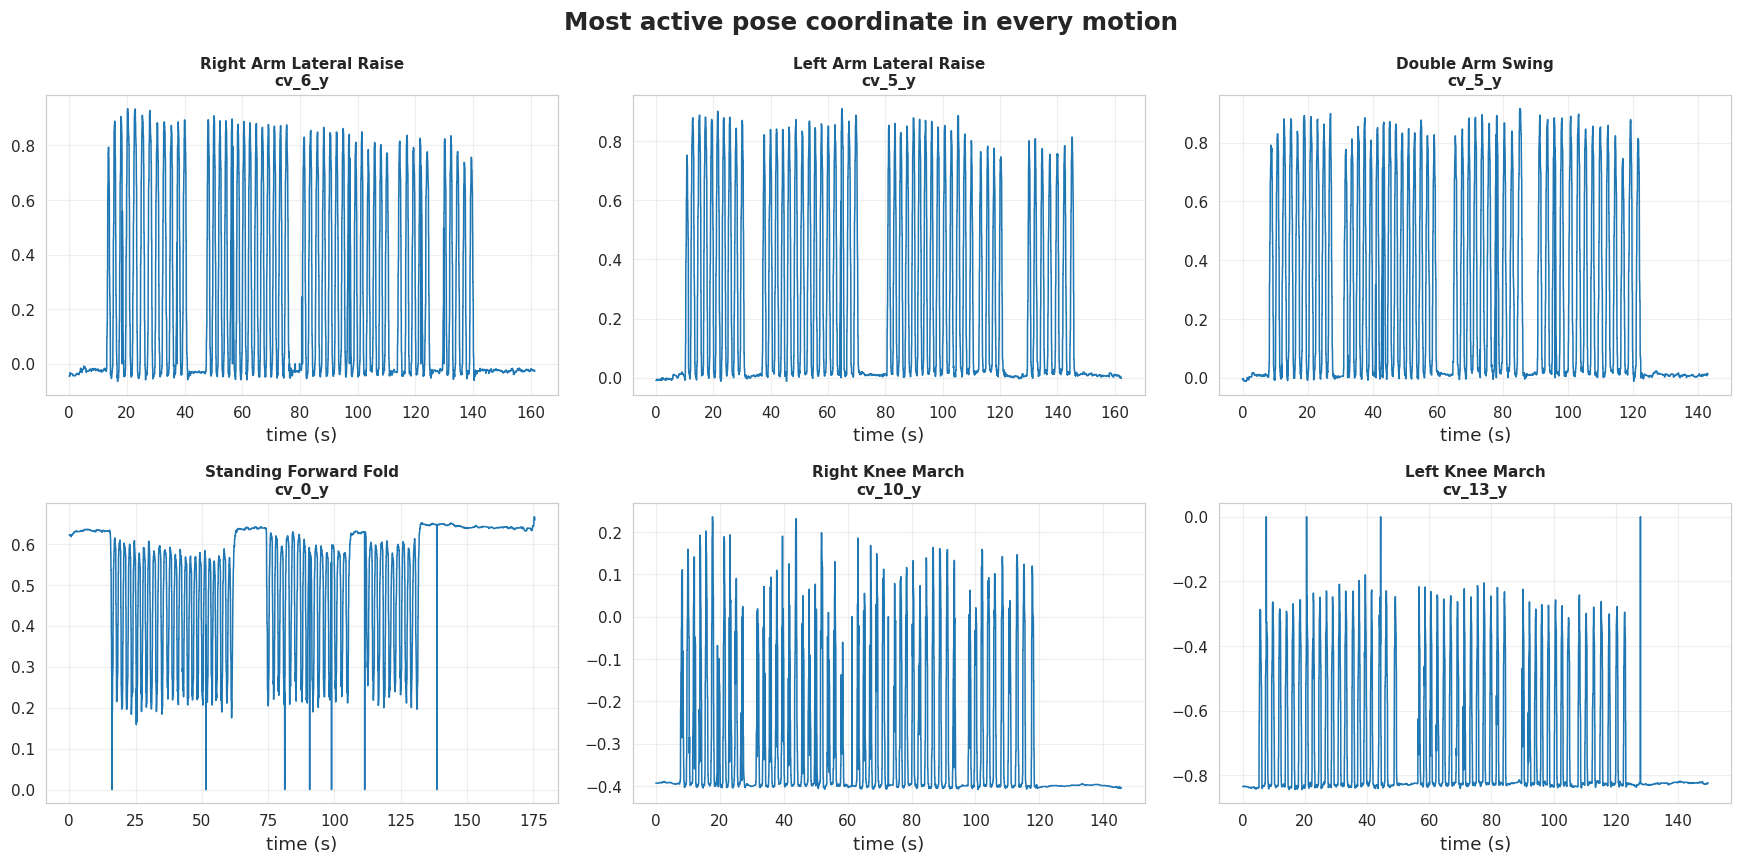

In [11]:
# Quick visual sanity check: the most active pose coordinate of every motion
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (m, d) in zip(axes.ravel(), MOTION_DATA.items()):
    j = int(np.argmax(d["Y_raw"].std(axis=0)))
    tt = d["t"] - d["t"][0]
    ax.plot(tt, d["Y_raw"][:, j], lw=1)
    ax.set_title(f"{m}\n{pose_cols[j]}", fontsize=10)
    ax.set_xlabel("time (s)")
for ax in axes.ravel()[len(MOTION_DATA):]:
    ax.axis("off")
plt.suptitle("Most active pose coordinate in every motion", fontsize=16, fontweight="bold")
plt.tight_layout()
savefig("all_motions_overview.png")
plt.show()

## 4. Model architectures

Identical to the single-motion notebook (MLP, 1D-CNN, GRU, LSTM, Transformer) with Gaussian input noise and
random *sensor dropout* during training only, L2 regularisation, and a skip path from the latest IMU frame
for the recurrent models.

In [14]:
L2 = keras.regularizers.l2(1e-4)

@keras.utils.register_keras_serializable(package="mocap")
class SensorDropout(layers.Layer):
    """Training-only: independently blank each sensor's channels (set to the train mean = 0)."""
    def __init__(self, n_sensors, channels=6, rate=0.05, **kwargs):
        super().__init__(**kwargs)
        self.n_sensors, self.channels, self.rate = n_sensors, channels, rate

    def call(self, x, training=None):
        if not training or self.rate <= 0:
            return x
        shape = tf.shape(x)
        x5 = tf.reshape(x, (shape[0], shape[1], self.n_sensors, self.channels))
        keep = tf.cast(tf.random.uniform((shape[0], 1, self.n_sensors, 1)) >= self.rate, x.dtype)
        return tf.reshape(x5 * keep, shape)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(n_sensors=self.n_sensors, channels=self.channels, rate=self.rate)
        return cfg


def _inputs(window_size, n_features):
    inp = layers.Input(shape=(window_size, n_features), name="imu_window")
    x = SensorDropout(n_features // 6, 6, SENSOR_DROPOUT)(inp)
    x = layers.GaussianNoise(NOISE_STD)(x)
    return inp, x

def last_step(x):
    return layers.Flatten()(layers.Cropping1D((x.shape[1] - 1, 0))(x))

def build_mlp(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="MLP")

def build_cnn1d(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Conv1D(32, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.Conv1D(64, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.SpatialDropout1D(0.2)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="CNN1D")

def _recurrent(cell_layer, name):
    def build(window_size, n_features, n_outputs):
        inp, x = _inputs(window_size, n_features)
        r = cell_layer(64)(x)
        r = layers.Dropout(0.3)(r)
        s = layers.Dense(32, activation="relu", kernel_regularizer=L2)(last_step(x))   # skip path
        h = layers.Concatenate()([r, s])
        h = layers.Dense(64, activation="relu", kernel_regularizer=L2)(h)
        h = layers.Dropout(0.2)(h)
        out = layers.Dense(n_outputs, name="pose_output")(h)
        return keras.Model(inp, out, name=name)
    return build

build_gru  = _recurrent(layers.GRU,  "GRU")
build_lstm = _recurrent(layers.LSTM, "LSTM")

@keras.utils.register_keras_serializable(package="mocap")
class PositionalEncoding(layers.Layer):
    def __init__(self, seq_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.seq_len, self.d_model = seq_len, d_model
        pos = np.arange(seq_len)[:, None]
        i = np.arange(d_model)[None, :]
        angle_rads = pos * (1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model)))
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        self.pos_encoding = tf.constant(angle_rads[None, ...], dtype=tf.float32)

    def call(self, x):
        return x + tf.cast(self.pos_encoding, x.dtype)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(seq_len=self.seq_len, d_model=self.d_model)
        return cfg

def transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout=0.2):
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)(x, x)
    attn = layers.Dropout(dropout)(attn)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn)
    ffn = layers.Dense(ff_dim, activation="relu", kernel_regularizer=L2)(x)
    ffn = layers.Dense(d_model, kernel_regularizer=L2)(ffn)
    ffn = layers.Dropout(dropout)(ffn)
    return layers.LayerNormalization(epsilon=1e-6)(x + ffn)

def build_transformer(window_size, n_features, n_outputs,
                      d_model=32, num_heads=2, ff_dim=64, num_blocks=1, dropout=0.2):
    inp, x = _inputs(window_size, n_features)
    x = layers.Dense(d_model)(x)
    x = PositionalEncoding(window_size, d_model)(x)
    for _ in range(num_blocks):
        x = transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="Transformer")

MODEL_BUILDERS = {"MLP": build_mlp, "CNN1D": build_cnn1d, "GRU": build_gru,
                  "LSTM": build_lstm, "Transformer": build_transformer}

for name, builder in MODEL_BUILDERS.items():
    m = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
    print(f"{name:12s} -> {m.count_params():,} parameters")
    del m

MLP          -> 50,099 parameters
CNN1D        -> 20,691 parameters
GRU          -> 28,947 parameters
LSTM         -> 34,835 parameters
Transformer  -> 17,011 parameters


## 5. Training and evaluation helpers

* **Weighted Huber loss** (per-column variance weights, floored) is built from the scaler of whatever dataset
  is being trained (one motion in Part A, all motions in Part C).
* **Seed ensemble**: `n_seeds` models of the same type are averaged. Parameter counts are per member, FPS is for the whole ensemble (batch `predict`, after a warm-up).
* **Metrics**: MAE, MSE, RMSE, **MPJPE** and four R² variants:
  `R2` variance-weighted, `R2 OOS` vs a constant train-mean forecast, `R2 active` (uniform R² over columns whose
  **train** variance is at least `ACTIVE_VAR_FRAC` x the mean column variance, a fixed set per dataset) and `R2 uniform` (reference only).
  Rank models with `MPJPE` and `R2 OOS`.
* **Model selection uses validation MPJPE only.**


In [15]:
def make_weighted_huber(pose_scaler, floor=LOSS_FLOOR, delta=1.0):
    s2 = pose_scaler.scale_ ** 2
    w = floor + (1 - floor) * (s2 / s2.mean())
    W = tf.constant(w / w.mean(), dtype=tf.float32)
    def weighted_huber(y_true, y_pred):
        err  = tf.abs(y_pred - y_true)
        quad = tf.minimum(err, delta)
        lin  = err - quad
        return tf.reduce_mean(W * (0.5 * quad ** 2 + delta * lin), axis=-1)
    return weighted_huber


class EnsembleModel:
    """Averages several Keras models."""
    def __init__(self, members):
        self.members = members

    def predict(self, X, verbose=0, **kwargs):
        preds = [np.asarray(m.predict(X, verbose=0, **kwargs), dtype="float64") for m in self.members]
        return np.mean(preds, axis=0)

    def count_params(self):                       # parameters of ONE member
        return int(self.members[0].count_params())

    @classmethod
    def load(cls, path):
        """Inverse of save(): loads <stem>_member*.keras into an ensemble."""
        stem = path[:-6] if path.endswith(".keras") else path
        files = sorted(glob.glob(f"{stem}_member*.keras"))
        if not files:
            raise FileNotFoundError(f"No ensemble members found for {stem}_member*.keras")
        return cls([keras.models.load_model(f, compile=False) for f in files])

    def save(self, path):
        stem = path[:-6] if path.endswith(".keras") else path
        for i, m in enumerate(self.members):
            m.save(f"{stem}_member{i}.keras")


def train_ensemble(model_name, builder, data, pose_scaler, n_seeds, batch_size, tag,
                   use_ckpt=False, verbose=True):
    """Train n_seeds models on data['train'], validate on data['val']. Returns (EnsembleModel, seed-0 history, seconds)."""
    X_tr, Y_tr = data["train"]; X_va, Y_va = data["val"]
    loss_fn = make_weighted_huber(pose_scaler)
    members, hist0, start = [], None, time.time()
    for k in range(n_seeds):
        tf.keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + k)
        model = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-3),
                      loss=loss_fn, metrics=["mae"])
        cbs = [
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, min_delta=1e-4,
                                          restore_best_weights=True, verbose=0),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=12,
                                              min_lr=1e-5, verbose=0),
        ]
        if use_ckpt:
            cbs.append(keras.callbacks.ModelCheckpoint(
                os.path.join(DIR_MODELS, f"{tag}_{model_name}_seed{k}_best.keras"),
                monitor="val_loss", save_best_only=True, verbose=0))
            cbs.append(keras.callbacks.TensorBoard(log_dir=os.path.join(DIR_LOGS, f"{tag}_{model_name}_seed{k}")))
        hist = model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=EPOCHS,
                         batch_size=batch_size, callbacks=cbs, verbose=0)
        h = hist.history
        best = int(np.argmin(h["val_loss"]))
        if verbose:
            print(f"    {model_name:11s} seed {k}: {len(h['loss']):3d} epochs | best {best + 1:3d} | "
                  f"train {h['loss'][best]:.4f} | val {h['val_loss'][best]:.4f}")
        members.append(model)
        if k == 0:
            hist0 = {key: [float(v) for v in vals] for key, vals in h.items()}
    return EnsembleModel(members), hist0, time.time() - start


# ---------------------------------------------------------------------------------
# Metrics
# ---------------------------------------------------------------------------------
ACTIVE_VAR_FRAC = 0.10   # a column is "active" if its TRAIN variance >= this x the mean column variance

def active_mask_from(var):
    var = np.asarray(var, dtype="float64")
    return var >= ACTIVE_VAR_FRAC * var.mean()

def mpjpe(y_true, y_pred, n_joints=N_JOINTS):
    yt = y_true.reshape(-1, n_joints, 3); yp = y_pred.reshape(-1, n_joints, 3)
    d = np.linalg.norm(yt - yp, axis=-1)
    return d.mean(), d.mean(axis=0)

def r2_time_series(y_true, y_pred, bench_mean, active_mask):
    sse   = ((y_true - y_pred) ** 2).sum(axis=0)
    sse_b = ((y_true - bench_mean) ** 2).sum(axis=0)          # benchmark: constant train mean
    return dict(
        r2         = r2_score(y_true, y_pred, multioutput="variance_weighted"),
        r2_oos     = 1.0 - sse.sum() / sse_b.sum(),
        r2_active  = r2_score(y_true[:, active_mask], y_pred[:, active_mask]),
        r2_uniform = r2_score(y_true, y_pred, multioutput="uniform_average"),
        n_active   = int(active_mask.sum()))

def compute_metrics(y_true, y_pred, pose_scaler, bench_mean=None, active_mask=None):
    """bench_mean / active_mask default to the scaler's train mean / train-variance mask. Pass a motion's own
    values to get per-motion numbers that are comparable with Part A."""
    bench_mean  = pose_scaler.mean_ if bench_mean is None else bench_mean
    active_mask = active_mask_from(pose_scaler.var_) if active_mask is None else active_mask
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    r2m  = r2_time_series(y_true, y_pred, bench_mean, active_mask)
    mp, per_joint = mpjpe(y_true, y_pred)
    return dict(mae=mae, mse=mse, rmse=float(np.sqrt(mse)), mpjpe=mp, per_joint_mpjpe=per_joint,
                y_true=y_true, y_pred=y_pred, **r2m)

def predict_orig(model, X, pose_scaler):
    p = np.asarray(model.predict(X, verbose=0), dtype="float64")
    return pose_scaler.inverse_transform(p).astype("float64")

def evaluate_split(model, X, Y_scaled, pose_scaler):
    y_true = pose_scaler.inverse_transform(Y_scaled).astype("float64")
    return compute_metrics(y_true, predict_orig(model, X, pose_scaler), pose_scaler)

def evaluate_all_splits(model, data, pose_scaler):
    """Returns train/val/test metrics, inference time (s) and FPS measured on the test split."""
    tr = evaluate_split(model, *data["train"], pose_scaler)
    va = evaluate_split(model, *data["val"],   pose_scaler)
    X_te, Y_te = data["test"]
    y_pred = predict_orig(model, X_te, pose_scaler)          # also warms the model up
    runs = []
    for _ in range(3):                                         # pure predict timing, median of 3
        t0 = time.perf_counter(); model.predict(X_te, verbose=0); runs.append(time.perf_counter() - t0)
    inf = float(np.median(runs))
    te = compute_metrics(pose_scaler.inverse_transform(Y_te).astype("float64"), y_pred, pose_scaler)
    return tr, va, te, inf, (len(X_te) / inf if inf > 0 else float("nan"))


class LastFrameSklearn:
    """Classical reference model that only sees the LATEST IMU frame of each window."""
    def __init__(self, est): self.est = est
    def fit(self, X, Y): self.est.fit(X[:, -1, :], Y); return self
    def predict(self, X, verbose=0): return self.est.predict(X[:, -1, :])

def make_reference_models():
    return {
        "Ridge (last frame)":      LastFrameSklearn(Ridge(alpha=10)),
        "ExtraTrees (last frame)": LastFrameSklearn(ExtraTreesRegressor(
            n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)),
    }

def make_row(scope, model_name, mtype, tr, va, te, n_params, train_time, fps):
    return dict(Motion=scope, Model=model_name, Type=mtype, Params=n_params,
                TrainTime_s=round(train_time, 2), FPS=round(fps, 1),
                Train_MPJPE=tr["mpjpe"], Val_MPJPE=va["mpjpe"],
                Test_MAE=te["mae"], Test_RMSE=te["rmse"], Test_MPJPE=te["mpjpe"],
                Test_R2=te["r2"], Test_R2_OOS=te["r2_oos"], Test_R2_active=te["r2_active"],
                Test_over_Train=te["mpjpe"] / max(tr["mpjpe"], 1e-12))


# ---------------------------------------------------------------------------------
# Windowing (inside each contiguous segment only)
# ---------------------------------------------------------------------------------
def create_sequences(X, Y, window_size=WINDOW_SIZE, stride=STRIDE):
    xs, ys = [], []
    for start in range(0, len(X) - window_size + 1, stride):
        end = start + window_size
        xs.append(X[start:end]); ys.append(Y[end - 1])
    return np.array(xs, dtype="float32"), np.array(ys, dtype="float32")

def split_arrays(X_scaled, Y_scaled, segments):
    parts = {"train": ([], []), "val": ([], []), "test": ([], [])}
    for nm, s, e in segments:
        xs, ys = create_sequences(X_scaled[s:e], Y_scaled[s:e])
        if len(xs):
            parts[nm][0].append(xs); parts[nm][1].append(ys)
    out = {}
    for k, (xl, yl) in parts.items():
        out[k] = (np.concatenate(xl), np.concatenate(yl)) if xl else \
                 (np.empty((0, WINDOW_SIZE, N_FEATURES), "float32"), np.empty((0, N_OUTPUTS), "float32"))
    return out

def train_row_indices(segments):
    return np.concatenate([np.arange(s, e) for nm, s, e in segments if nm == "train"])

## 6. Skeleton / plotting helpers

In [18]:
KEYPOINT_NAMES = ["Head", "Left Shoulder", "Right Shoulder", "Left Elbow", "Right Elbow",
                  "Left Wrist", "Right Wrist", "Left Hip", "Right Hip", "Left Knee", "Right Knee",
                  "Left Ankle", "Right Ankle", "Left Heel", "Right Heel",
                  "Left Foot Index", "Right Foot Index"]

SKELETON_CONNECTIONS = [(1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8),
                        (7, 9), (9, 11), (11, 13), (13, 15), (8, 10), (10, 12), (12, 14), (14, 16)]

_VIEW_AXES = {"X": (1, 2, "Y", "Z"), "Y": (0, 2, "X", "Z"), "Z": (0, 1, "X", "Y")}

def plot_projection(ax, coords, body_color, view, title=""):
    ix, iy, xl, yl = _VIEW_AXES[view]
    x, y = coords[:, ix], coords[:, iy]
    ax.scatter(x[1:], y[1:], color=body_color, s=40)
    ax.scatter(x[0], y[0], color="blue", s=80)
    for a, b in SKELETON_CONNECTIONS:
        ax.plot([x[a], x[b]], [y[a], y[b]], color=body_color, linewidth=2)
    sm = (coords[1] + coords[2]) / 2
    ax.plot([x[0], sm[ix]], [y[0], sm[iy]], color="blue", linewidth=3)
    if title: ax.set_title(title, fontsize=11, weight="bold")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.axis("equal"); ax.grid(True)

def plot_skeleton_3x3(true_coords, pred_coords, title, fname):
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    for row, view in enumerate(["X", "Y", "Z"]):
        plot_projection(axes[row, 0], true_coords, "green", view, f"Ground Truth - {view} View")
        plot_projection(axes[row, 1], pred_coords, "red", view, f"Prediction - {view} View")
        plot_projection(axes[row, 2], true_coords, "green", view)
        plot_projection(axes[row, 2], pred_coords, "red", view, f"Overlay - {view} View")
    plt.suptitle(title, fontsize=18, weight="bold")
    plt.tight_layout(); savefig(fname); plt.show()

# PART A — Per-motion experiments (6 motions)

For every motion the full pipeline of the single-motion notebook is repeated:

`scale (train rows only) -> windows -> train 5 models -> evaluate -> 2 reference baselines -> save`

One summary figure per motion is shown (loss curves, prediction vs ground truth of the most active
coordinate, per-joint MPJPE of the best model). Results are cached in `results/per_motion/`, so if the
session stops you can re-run and it will continue with the motions not yet finished (`RESUME = True`).

In [17]:
def plot_motion_summary(name, histories, results, best_name):
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
    for mn, h in histories.items():
        axes[0].plot(h["val_loss"], label=mn)
    axes[0].set_title(f"{name}: validation loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Weighted Huber")
    axes[0].legend(fontsize=8)

    yt, yp = results[best_name]["test"]["y_true"], results[best_name]["test"]["y_pred"]
    j = int(np.argmax(yt.std(axis=0)))
    axes[1].plot(yt[:, j], lw=2, label="Ground truth"); axes[1].plot(yp[:, j], "--", lw=2, label="Predicted")
    for sm in test_seams(MOTION_DATA[name]["segments"]):
        axes[1].axvline(sm - 0.5, color="gray", linestyle=":", lw=1)
    axes[1].set_title(f"{best_name}: {pose_cols[j]} (test, dotted = block seam)"); axes[1].set_xlabel("Test window"); axes[1].legend()

    axes[2].bar(range(N_JOINTS), results[best_name]["test"]["per_joint_mpjpe"], color="cornflowerblue")
    axes[2].set_xticks(range(N_JOINTS)); axes[2].set_xticklabels(KEYPOINT_NAMES, rotation=70, ha="right", fontsize=8)
    axes[2].set_title(f"{best_name}: per-joint MPJPE (test)")
    plt.suptitle(f"Motion: {name}", fontsize=15, fontweight="bold")
    plt.tight_layout(); savefig(f"motion_{safe_name(name)}_summary.png"); plt.show()


def run_motion(name):
    cache = os.path.join(DIR_PM, f"{safe_name(name)}_{CONFIG_TAG}_summary.csv")
    if RESUME and os.path.exists(cache):
        print(f"[{name}] cached -> {cache} (skipping training)")
        return pd.read_csv(cache)

    md_ = MOTION_DATA[name]
    tr_rows = train_row_indices(md_["segments"])
    imu_sc, pose_sc = fit_scalers(md_["X_raw"][tr_rows], md_["Y_raw"][tr_rows])
    joblib.dump(imu_sc,  os.path.join(DIR_SCALERS, f"{safe_name(name)}_imu_scaler.joblib"))
    joblib.dump(pose_sc, os.path.join(DIR_SCALERS, f"{safe_name(name)}_pose_scaler.joblib"))

    data = split_arrays(scale_imu(imu_sc, md_["X_raw"]),
                        pose_sc.transform(md_["Y_raw"]).astype("float32"), md_["segments"])
    print(f"[{name}] windows -> train {len(data['train'][0])} | val {len(data['val'][0])} | test {len(data['test'][0])}")

    results, histories, ensembles, rows = {}, {}, {}, []
    for mn, builder in MODEL_BUILDERS.items():
        ens, hist, secs = train_ensemble(mn, builder, data, pose_sc, N_SEEDS_MOTION, BATCH_SIZE, safe_name(name))
        tr, va, te, inf, fps = evaluate_all_splits(ens, data, pose_sc)
        results[mn] = dict(train=tr, val=va, test=te)
        histories[mn], ensembles[mn] = hist, ens
        rows.append(make_row(name, mn, "deep", tr, va, te, ens.count_params(), secs, fps))

    for rn, rm in make_reference_models().items():
        t0 = time.time(); rm.fit(*[data["train"][0], data["train"][1]]); secs = time.time() - t0
        tr, va, te, inf, fps = evaluate_all_splits(rm, data, pose_sc)
        rows.append(make_row(name, rn, "reference", tr, va, te, 0, secs, fps))

    rows_df = pd.DataFrame(rows)
    rows_df.to_csv(cache, index=False)

    deep_df = rows_df[rows_df.Type == "deep"]
    best_name = deep_df.loc[deep_df.Val_MPJPE.idxmin(), "Model"]      # selected on VALIDATION MPJPE
    ensembles[best_name].save(os.path.join(DIR_MODELS, f"{safe_name(name)}_best_{best_name}.keras"))
    with open(os.path.join(DIR_PM, f"{safe_name(name)}_history.json"), "w") as f:
        json.dump(histories, f)
    np.save(os.path.join(DIR_PM, f"{safe_name(name)}_y_pred_test_{best_name}.npy"), results[best_name]["test"]["y_pred"])

    print(f"[{name}] best deep model (by val MPJPE): {best_name} | Test MPJPE "
          f"{deep_df.loc[deep_df.Val_MPJPE.idxmin(), 'Test_MPJPE']:.5f}")
    plot_motion_summary(name, histories, results, best_name)
    return rows_df

### Run all 6 motions

This is the long-running cell. Progress is printed per motion; each finished motion is cached to disk.


MOTION 1/6: Right Arm Lateral Raise
[Right Arm Lateral Raise] windows -> train 2080 | val 480 | test 491
    MLP         seed 0: 215 epochs | best 209 | train 0.0439 | val 0.0506
    CNN1D       seed 0: 178 epochs | best 144 | train 0.0473 | val 0.0513
    GRU         seed 0: 153 epochs | best 113 | train 0.0402 | val 0.0477
    LSTM        seed 0: 144 epochs | best 104 | train 0.0381 | val 0.0477
    Transformer seed 0: 183 epochs | best 143 | train 0.0391 | val 0.0490
[Right Arm Lateral Raise] best deep model (by val MPJPE): LSTM | Test MPJPE 0.01306
Saved figure -> figures/motion_Right_Arm_Lateral_Raise_summary.png


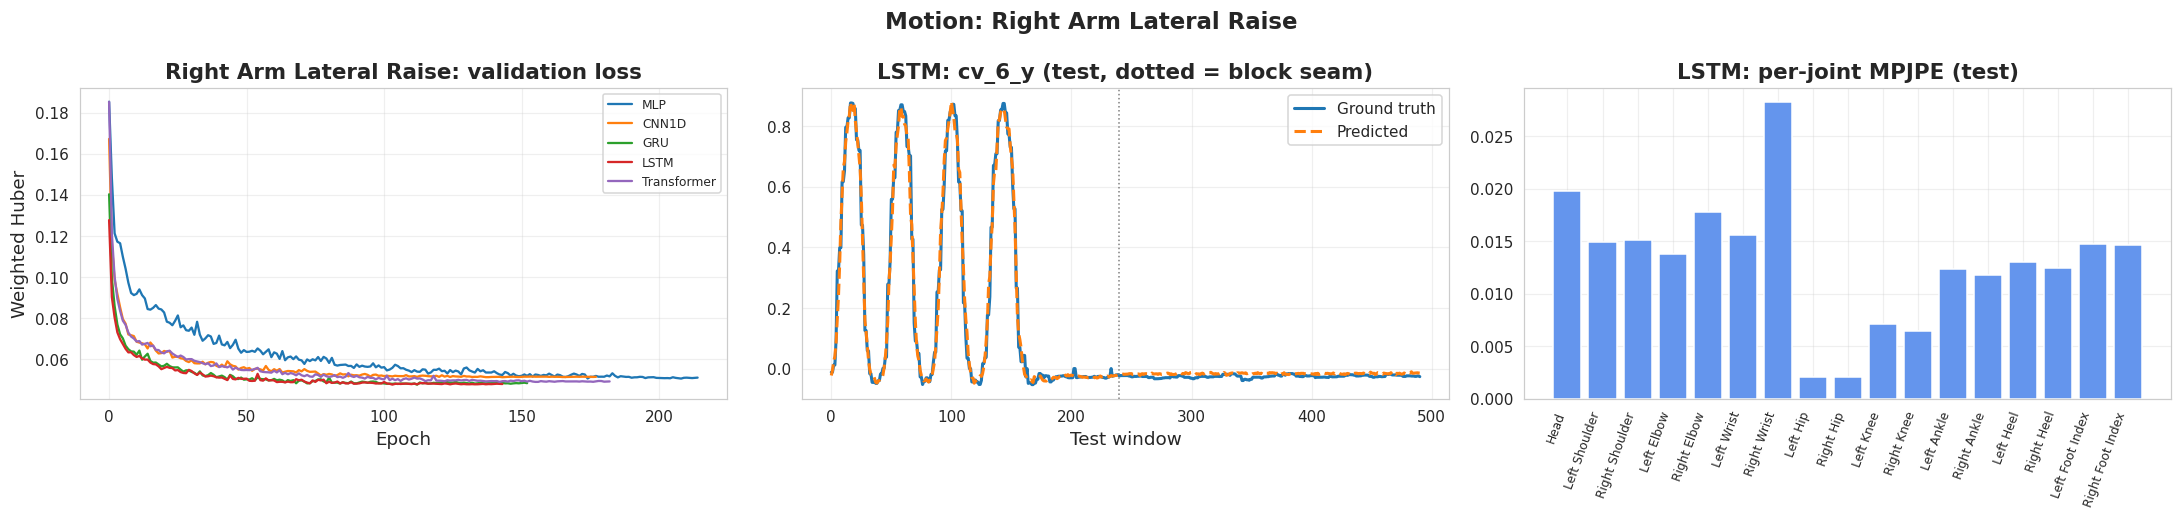

-- elapsed so far: 5.6 min

MOTION 2/6: Left Arm Lateral Raise
[Left Arm Lateral Raise] windows -> train 2092 | val 484 | test 494
    MLP         seed 0: 177 epochs | best 137 | train 0.0543 | val 0.0513
    CNN1D       seed 0: 101 epochs | best  61 | train 0.0588 | val 0.0488
    GRU         seed 0:  59 epochs | best  19 | train 0.0689 | val 0.0542
    LSTM        seed 0:  75 epochs | best  35 | train 0.0527 | val 0.0577
    Transformer seed 0:  77 epochs | best  37 | train 0.0596 | val 0.0532
[Left Arm Lateral Raise] best deep model (by val MPJPE): Transformer | Test MPJPE 0.00939
Saved figure -> figures/motion_Left_Arm_Lateral_Raise_summary.png


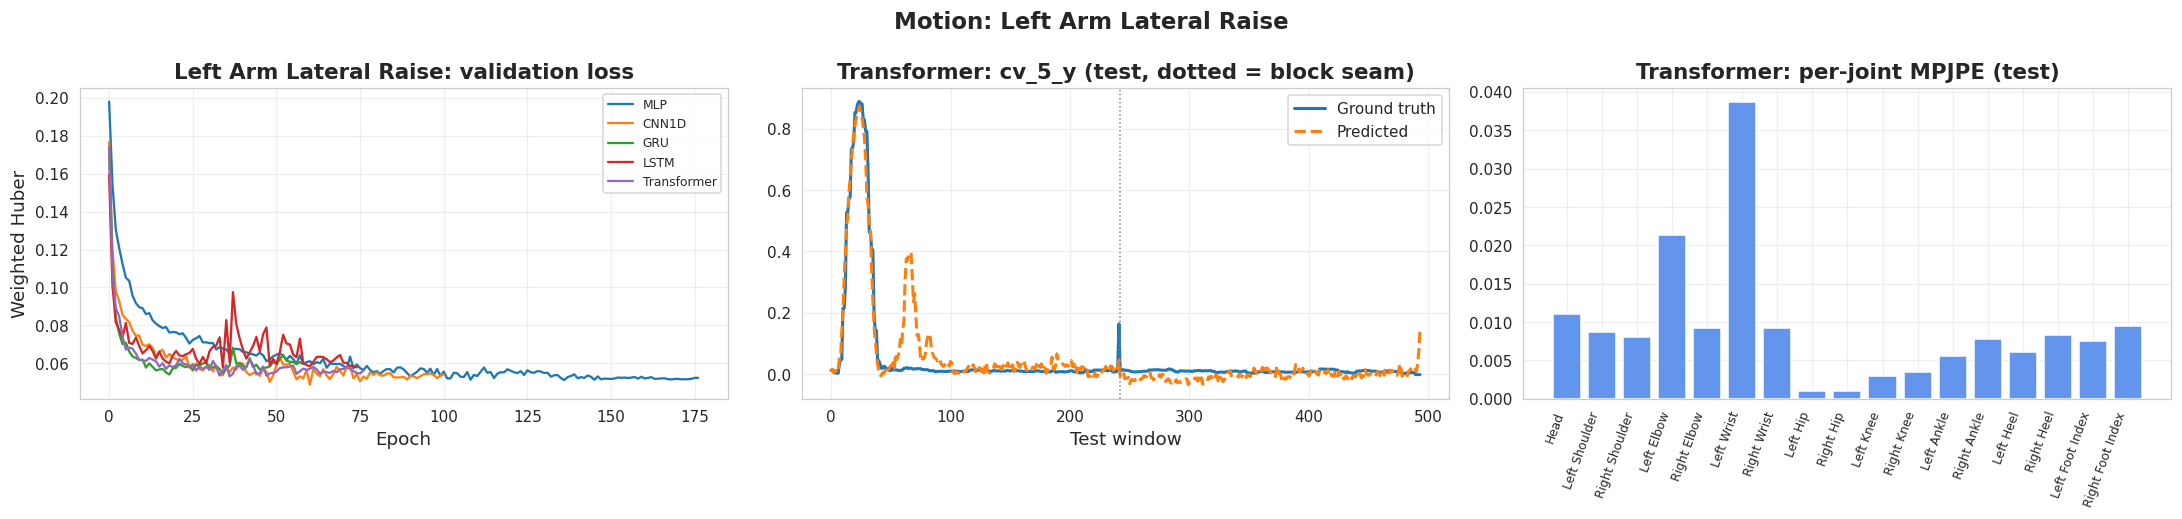

-- elapsed so far: 8.8 min

MOTION 3/6: Double Arm Swing
[Double Arm Swing] windows -> train 1838 | val 420 | test 430
    MLP         seed 0: 134 epochs | best 118 | train 0.0646 | val 0.0528
    CNN1D       seed 0: 121 epochs | best  81 | train 0.0657 | val 0.0478
    GRU         seed 0:  96 epochs | best  56 | train 0.0604 | val 0.0460
    LSTM        seed 0:  79 epochs | best  39 | train 0.0620 | val 0.0472
    Transformer seed 0: 152 epochs | best 112 | train 0.0591 | val 0.0480
[Double Arm Swing] best deep model (by val MPJPE): CNN1D | Test MPJPE 0.01170
Saved figure -> figures/motion_Double_Arm_Swing_summary.png


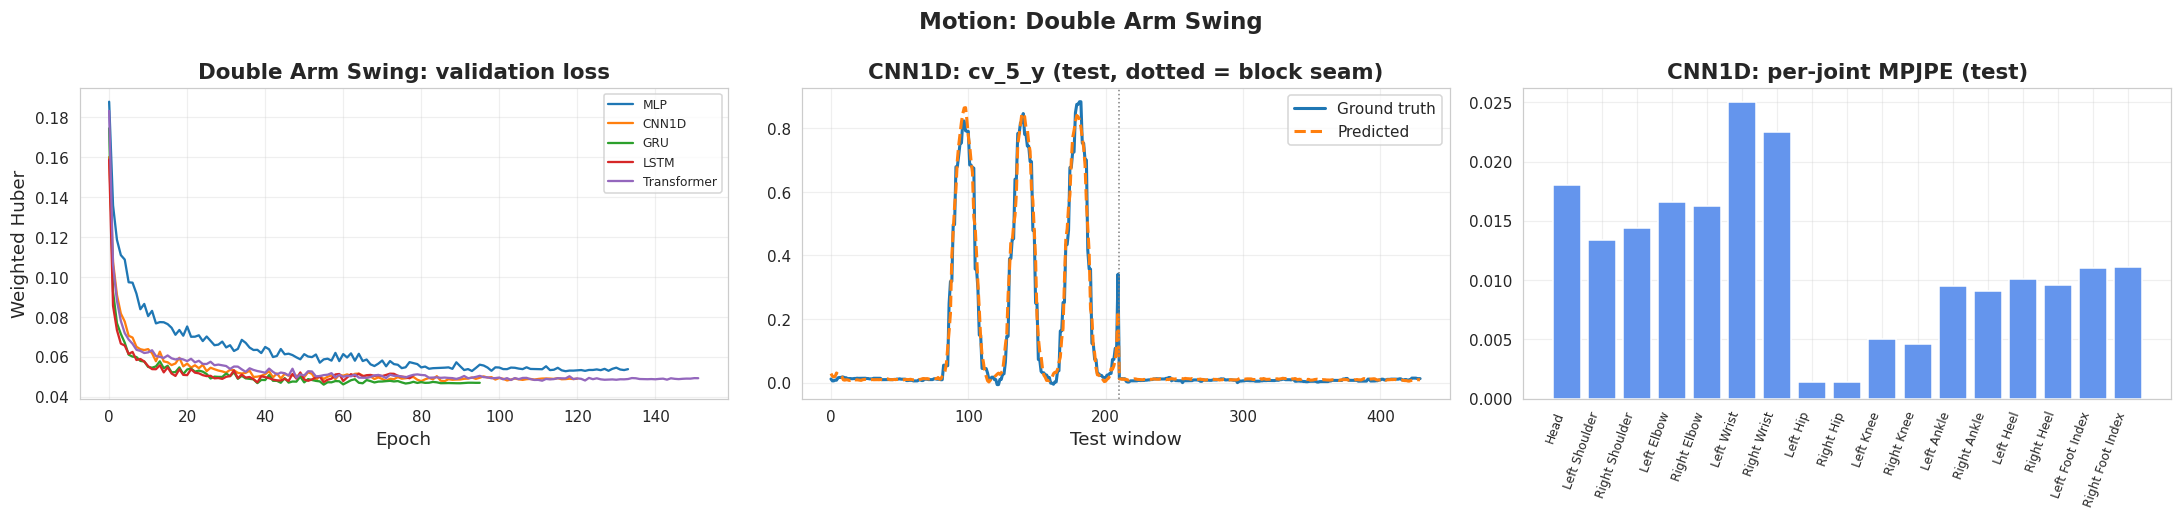

-- elapsed so far: 12.4 min

MOTION 4/6: Standing Forward Fold
[Standing Forward Fold] windows -> train 2268 | val 528 | test 538
    MLP         seed 0: 142 epochs | best 102 | train 0.0559 | val 0.0963
    CNN1D       seed 0:  84 epochs | best  44 | train 0.0595 | val 0.0985
    GRU         seed 0: 134 epochs | best 117 | train 0.0453 | val 0.0893
    LSTM        seed 0: 138 epochs | best  98 | train 0.0467 | val 0.0898
    Transformer seed 0: 111 epochs | best  71 | train 0.0513 | val 0.0955
[Standing Forward Fold] best deep model (by val MPJPE): GRU | Test MPJPE 0.03096
Saved figure -> figures/motion_Standing_Forward_Fold_summary.png


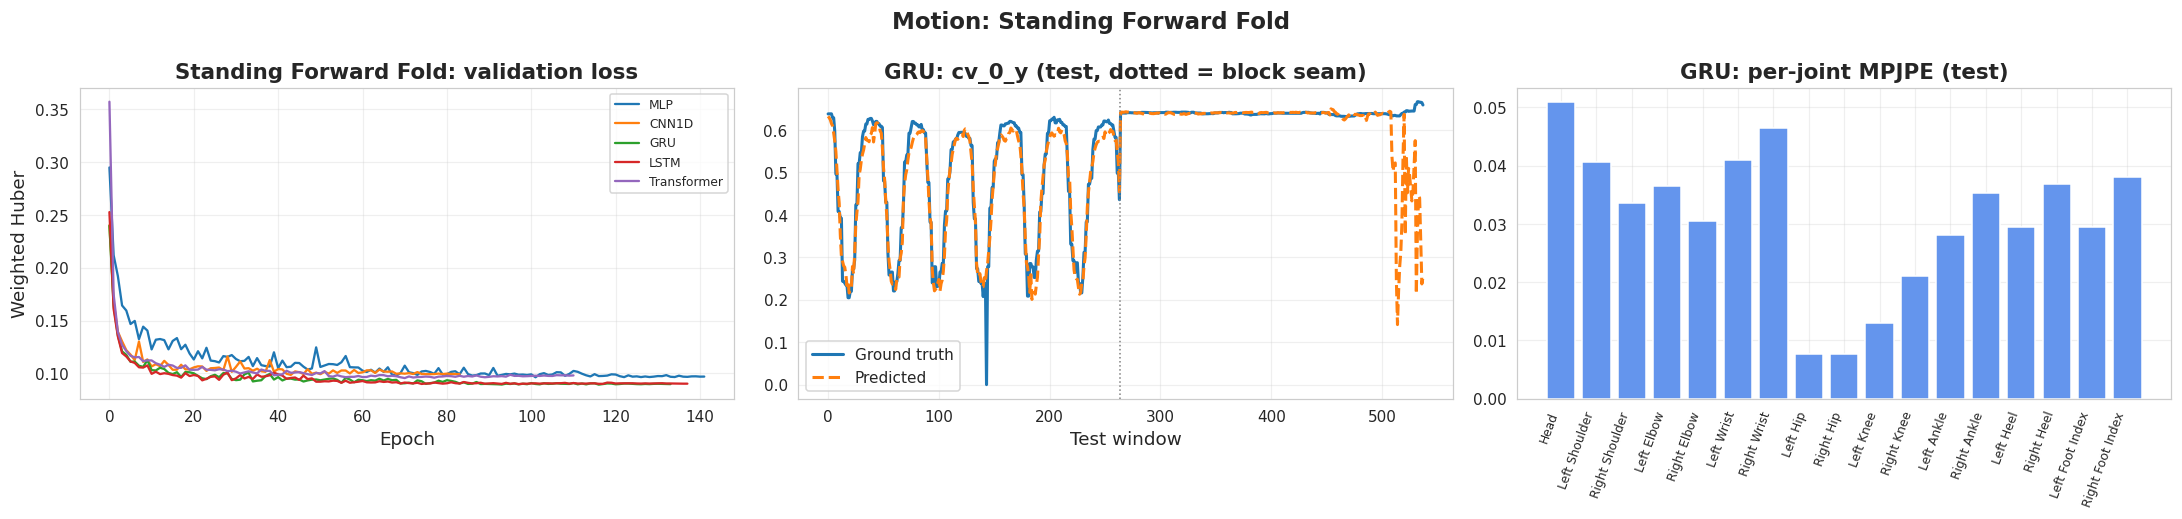

-- elapsed so far: 16.8 min

MOTION 5/6: Right Knee March
[Right Knee March] windows -> train 1871 | val 428 | test 438
    MLP         seed 0: 177 epochs | best 137 | train 0.0749 | val 0.1589
    CNN1D       seed 0:  57 epochs | best  17 | train 0.1360 | val 0.1701
    GRU         seed 0:  70 epochs | best  30 | train 0.0980 | val 0.1592
    LSTM        seed 0:  69 epochs | best  29 | train 0.0839 | val 0.1475
    Transformer seed 0:  58 epochs | best  18 | train 0.1336 | val 0.1645
[Right Knee March] best deep model (by val MPJPE): LSTM | Test MPJPE 0.02691
Saved figure -> figures/motion_Right_Knee_March_summary.png


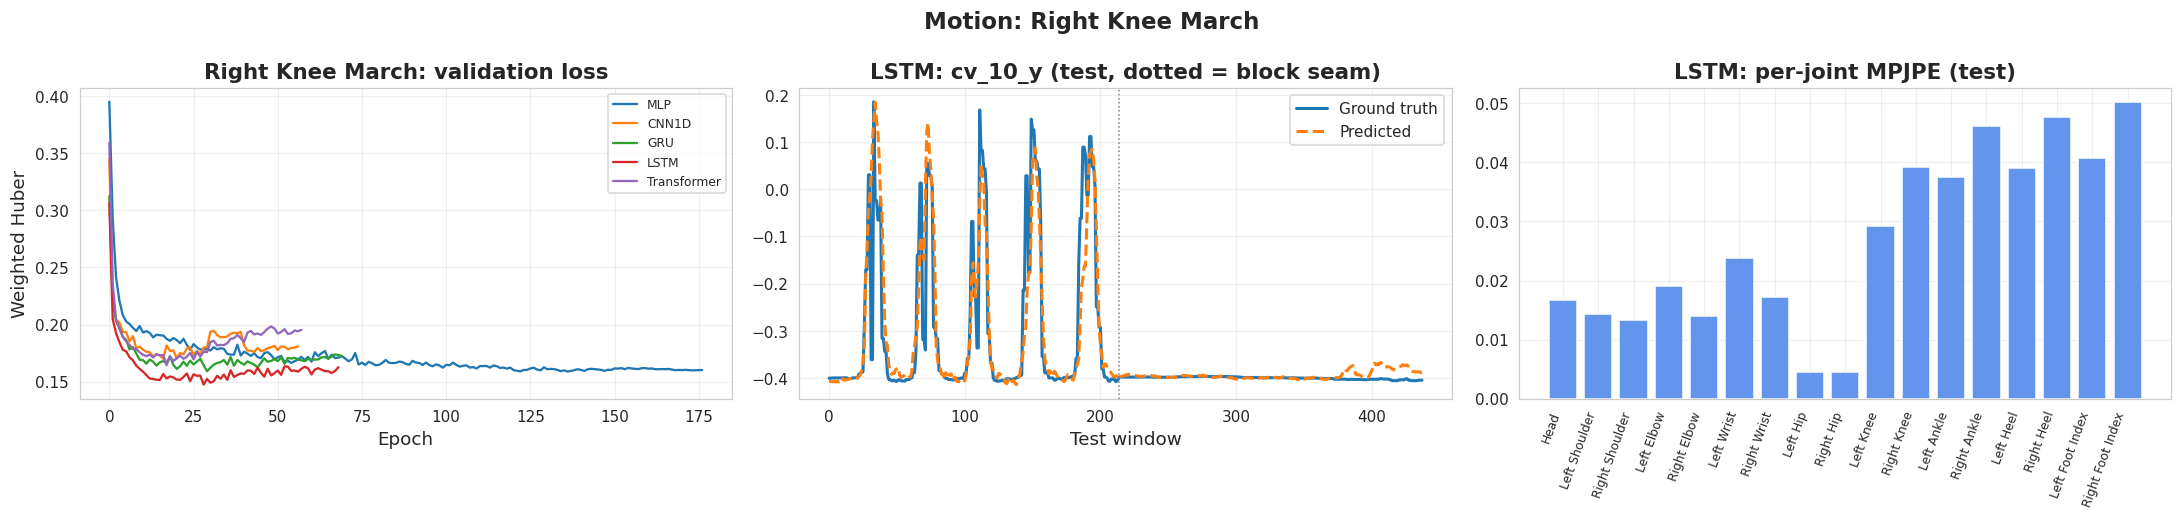

-- elapsed so far: 19.5 min

MOTION 6/6: Left Knee March
[Left Knee March] windows -> train 1924 | val 440 | test 452
    MLP         seed 0: 131 epochs | best  93 | train 0.0651 | val 0.0723
    CNN1D       seed 0:  55 epochs | best  15 | train 0.0854 | val 0.0680
    GRU         seed 0:  54 epochs | best  14 | train 0.0805 | val 0.0630
    LSTM        seed 0:  54 epochs | best  14 | train 0.0744 | val 0.0634
    Transformer seed 0:  97 epochs | best  57 | train 0.0559 | val 0.0606
[Left Knee March] best deep model (by val MPJPE): Transformer | Test MPJPE 0.01920
Saved figure -> figures/motion_Left_Knee_March_summary.png


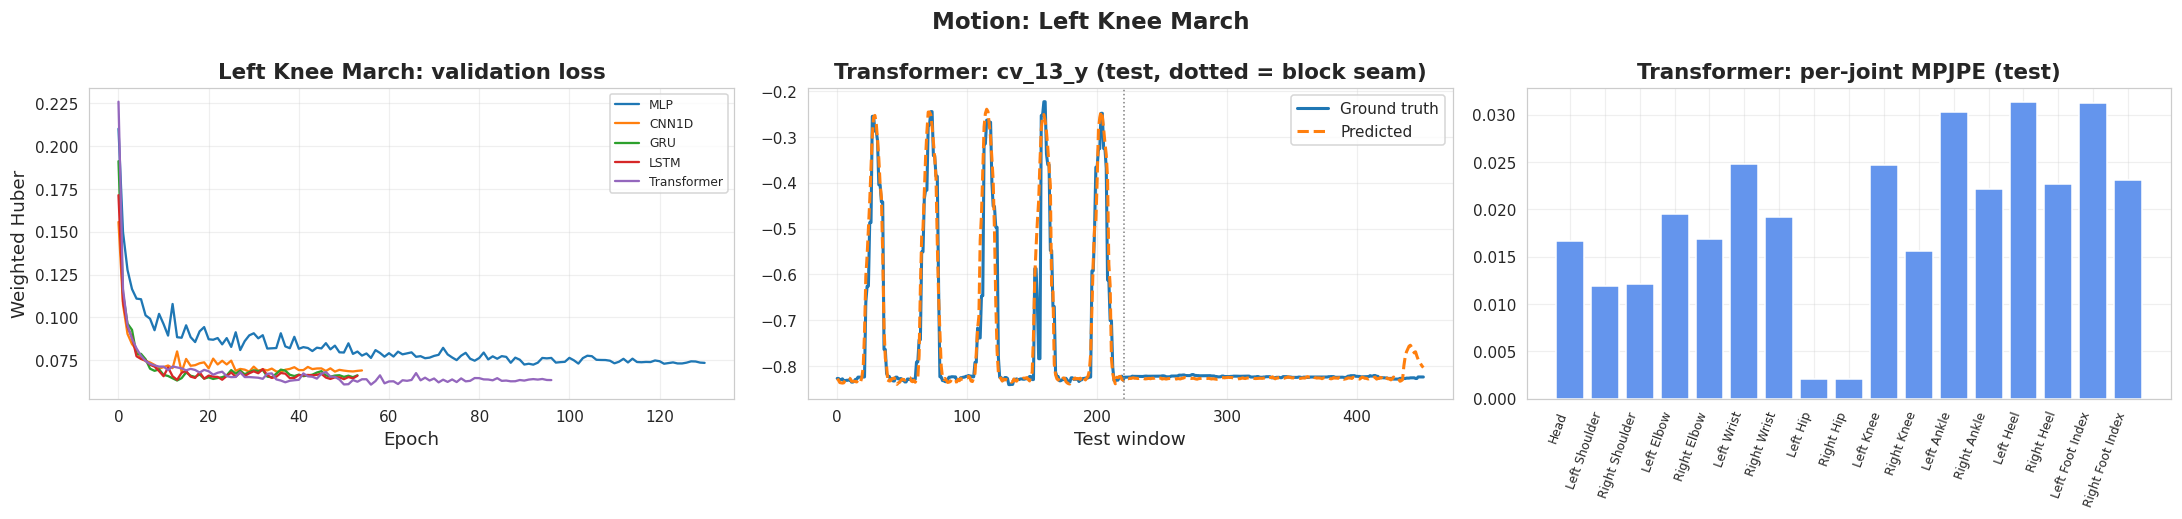

-- elapsed so far: 22.2 min

Part A finished: 6 motions x 7 models.


In [19]:
ALL_ROWS = []
t_start = time.time()
for i, m in enumerate(MOTIONS, 1):
    print("\n" + "=" * 90)
    print(f"MOTION {i}/{len(MOTIONS)}: {m}")
    print("=" * 90)
    ALL_ROWS.append(run_motion(m))
    print(f"-- elapsed so far: {(time.time() - t_start) / 60:.1f} min")

summary_df = pd.concat(ALL_ROWS, ignore_index=True)
summary_df["Motion"] = pd.Categorical(summary_df["Motion"], categories=MOTIONS, ordered=True)
summary_df = summary_df.sort_values(["Motion", "Type", "Test_MPJPE"]).reset_index(drop=True)
summary_df.to_csv(os.path.join(DIR_RESULTS, "all_motions_all_models.csv"), index=False)
print(f"\nPart A finished: {summary_df.Motion.nunique()} motions x {summary_df.groupby('Motion').size().iloc[0]} models.")

# PART B — Summary of all motion results

Everything below is computed from the table `summary_df` produced in Part A (also saved as
`results/all_motions_all_models.csv`). Metrics are on the **test split in original units**.

In [20]:
# TABLE 1 — every motion x every model
cols = ["Motion", "Model", "Type", "Params", "TrainTime_s", "FPS", "Train_MPJPE", "Val_MPJPE",
        "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active", "Test_over_Train"]
table1 = summary_df[cols].copy()
print("TABLE 1: ALL MOTIONS x ALL MODELS (test split)")
display(table1.style.format({c: "{:.5f}" for c in ["Train_MPJPE", "Val_MPJPE", "Test_MAE", "Test_RMSE",
                                                  "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                            | {"Test_over_Train": "{:.2f}", "Params": "{:,}"})
        .hide(axis="index"))

TABLE 1: ALL MOTIONS x ALL MODELS (test split)


Motion,Model,Type,Params,TrainTime_s,FPS,Train_MPJPE,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Test_over_Train
Right Arm Lateral Raise,LSTM,deep,"34,835",59.690000,3676.300000,0.01030,0.01460,0.00606,0.03172,0.01306,0.72413,0.76148,0.45790,1.27
Right Arm Lateral Raise,Transformer,deep,"17,011",96.940000,3584.100000,0.01062,0.01475,0.00605,0.03186,0.01316,0.72176,0.75942,0.45567,1.24
Right Arm Lateral Raise,GRU,deep,"28,947",65.890000,3968.400000,0.01068,0.01463,0.00610,0.03178,0.01316,0.72305,0.76054,0.45671,1.23
Right Arm Lateral Raise,CNN1D,deep,"20,691",51.790000,4228.200000,0.01084,0.01473,0.00612,0.03185,0.01324,0.72179,0.75945,0.45459,1.22
Right Arm Lateral Raise,MLP,deep,"50,099",50.810000,4523.800000,0.01051,0.01482,0.00628,0.03197,0.01354,0.71972,0.75766,0.45355,1.29
Right Arm Lateral Raise,ExtraTrees (last frame),reference,0,1.510000,3475.300000,0.01028,0.01649,0.00615,0.03205,0.01337,0.71833,0.75646,0.45021,1.30
Right Arm Lateral Raise,Ridge (last frame),reference,0,0.040000,1337171.500000,0.01933,0.02152,0.00834,0.03381,0.01774,0.68661,0.72903,0.42325,0.92
Left Arm Lateral Raise,CNN1D,deep,"20,691",31.210000,4211.700000,0.01089,0.01291,0.00411,0.01152,0.00853,0.82621,0.95194,0.49114,0.78
Left Arm Lateral Raise,MLP,deep,"50,099",44.280000,4175.800000,0.00988,0.01336,0.00415,0.01165,0.00871,0.82236,0.95087,0.49959,0.88
Left Arm Lateral Raise,Transformer,deep,"17,011",43.640000,3523.200000,0.01158,0.01288,0.00453,0.01243,0.00939,0.79766,0.94404,0.45415,0.81


In [21]:
# TABLE 2: best deep model per motion, selected on VALIDATION MPJPE (test is only reported)
deep = summary_df[summary_df.Type == "deep"].copy()
deep["Motion"] = deep["Motion"].astype(str)
best_idx = deep.groupby("Motion")["Val_MPJPE"].idxmin()
table2 = deep.loc[best_idx].set_index("Motion").loc[MOTIONS].reset_index()
ref = summary_df[summary_df.Type == "reference"].assign(Motion=lambda d: d.Motion.astype(str))
ref_best = ref.loc[ref.groupby("Motion")["Val_MPJPE"].idxmin()].set_index("Motion")["Test_MPJPE"].rename("Best_reference_MPJPE")
table2 = table2.merge(ref_best, on="Motion", how="left")
table2["Beats_reference"] = table2["Test_MPJPE"] < table2["Best_reference_MPJPE"]
table2["Group"] = table2["Motion"].map(lambda m: MOTION_INFO[m]["Group"])
table2 = table2[["Motion", "Group", "Model", "Val_MPJPE", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS",
                 "Test_R2_active", "Best_reference_MPJPE", "Beats_reference", "FPS", "Params"]]
table2.to_csv(os.path.join(DIR_RESULTS, "best_model_per_motion.csv"), index=False)
print("TABLE 2: BEST DEEP MODEL PER MOTION (selected on validation MPJPE)")
display(table2.style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2",
                                                  "Test_R2_OOS", "Test_R2_active", "Best_reference_MPJPE"]}
                            | {"Params": "{:,}"}).hide(axis="index"))
print("\nMean over the 6 motions of the best model: "
      f"MPJPE {table2.Test_MPJPE.mean():.5f} | R2 OOS {table2.Test_R2_OOS.mean():.4f} | R2 {table2.Test_R2.mean():.4f}")
print("\nBest-model results averaged by body group (arm / trunk / leg):")
display(table2.groupby("Group")[["Test_MPJPE", "Test_R2_OOS", "Test_R2"]].mean()
        .style.format("{:.5f}"))

TABLE 2: BEST DEEP MODEL PER MOTION (selected on validation MPJPE)


Motion,Group,Model,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Best_reference_MPJPE,Beats_reference,FPS,Params
Right Arm Lateral Raise,Arm,LSTM,0.014605,0.00606,0.03172,0.01306,0.72413,0.76148,0.45790,0.01337,True,3676.300000,"34,835"
Left Arm Lateral Raise,Arm,Transformer,0.012879,0.00453,0.01243,0.00939,0.79766,0.94404,0.45415,0.01247,True,3523.200000,"17,011"
Double Arm Swing,Arm,CNN1D,0.018430,0.00553,0.02510,0.01170,0.84322,0.89515,0.48198,0.01190,True,3816.000000,"20,691"
Standing Forward Fold,Trunk,GRU,0.032859,0.01482,0.03995,0.03096,0.61637,0.61991,0.48671,0.02647,False,4209.700000,"28,947"
Right Knee March,Leg,LSTM,0.037685,0.01334,0.03252,0.02691,0.70768,0.72407,0.65742,0.02874,True,3472.100000,"34,835"
Left Knee March,Leg,Transformer,0.023029,0.00937,0.02121,0.01920,0.86516,0.87437,0.63577,0.01723,False,3228.000000,"17,011"



Mean over the 6 motions of the best model: MPJPE 0.01853 | R2 OOS 0.8032 | R2 0.7590

Best-model results averaged by body group (arm / trunk / leg):


,Test_MPJPE,Test_R2_OOS,Test_R2
Group,,,
Arm,0.01138,0.86689,0.78834
Leg,0.02305,0.79922,0.78642
Trunk,0.03096,0.61991,0.61637


In [22]:
# TABLE 3 — Test MPJPE matrix (motion x model), lower is better
mpjpe_matrix = summary_df.assign(Motion=summary_df.Motion.astype(str)).pivot(index="Motion", columns="Model", values="Test_MPJPE").loc[MOTIONS]
deep_cols = list(MODEL_BUILDERS)
mpjpe_matrix = mpjpe_matrix[deep_cols + [c for c in mpjpe_matrix.columns if c not in deep_cols]]
mpjpe_matrix.to_csv(os.path.join(DIR_RESULTS, "mpjpe_matrix_motion_x_model.csv"))
print("TABLE 3: TEST MPJPE (rows = motions, columns = models; green = best in row)")
display(mpjpe_matrix.style.format("{:.5f}").highlight_min(axis=1, color="lightgreen"))

r2_matrix = summary_df.assign(Motion=summary_df.Motion.astype(str)).pivot(index="Motion", columns="Model", values="Test_R2_OOS").loc[MOTIONS]
r2_matrix = r2_matrix[mpjpe_matrix.columns]
r2_matrix.to_csv(os.path.join(DIR_RESULTS, "r2_oos_matrix_motion_x_model.csv"))
print("\nTABLE 3b: TEST R2 OOS vs train-mean forecast (higher is better; > 0 beats the benchmark)")
display(r2_matrix.style.format("{:.4f}").highlight_max(axis=1, color="lightgreen"))

TABLE 3: TEST MPJPE (rows = motions, columns = models; green = best in row)


Model,MLP,CNN1D,GRU,LSTM,Transformer,ExtraTrees (last frame),Ridge (last frame)
Motion,,,,,,,
Right Arm Lateral Raise,0.01354,0.01324,0.01316,0.01306,0.01316,0.01337,0.01774
Left Arm Lateral Raise,0.00871,0.00853,0.01037,0.01020,0.00939,0.01247,0.02022
Double Arm Swing,0.01193,0.01170,0.01150,0.01210,0.01162,0.01190,0.01733
Standing Forward Fold,0.02715,0.02672,0.03096,0.02986,0.02821,0.02647,0.04087
Right Knee March,0.02727,0.02994,0.02920,0.02691,0.02940,0.02874,0.03853
Left Knee March,0.01891,0.01978,0.02047,0.01982,0.01920,0.01723,0.02614



TABLE 3b: TEST R2 OOS vs train-mean forecast (higher is better; > 0 beats the benchmark)


Model,MLP,CNN1D,GRU,LSTM,Transformer,ExtraTrees (last frame),Ridge (last frame)
Motion,,,,,,,
Right Arm Lateral Raise,0.7577,0.7594,0.7605,0.7615,0.7594,0.7565,0.7290
Left Arm Lateral Raise,0.9509,0.9519,0.9322,0.8996,0.9440,0.9179,0.7760
Double Arm Swing,0.8935,0.8951,0.8955,0.8946,0.8956,0.8928,0.8676
Standing Forward Fold,0.7719,0.7845,0.6199,0.6609,0.7711,0.7909,0.5760
Right Knee March,0.7296,0.6171,0.6167,0.7241,0.6360,0.6875,0.5356
Left Knee March,0.8754,0.8713,0.8655,0.8677,0.8744,0.9045,0.8049


In [23]:
# TABLE 4 — average performance of every model across the 6 motions
rank_mat = mpjpe_matrix[deep_cols].rank(axis=1, method="min")
avg = (summary_df.assign(Motion=summary_df.Motion.astype(str)).groupby("Model")
       .agg(Mean_MAE=("Test_MAE", "mean"), Mean_RMSE=("Test_RMSE", "mean"), Mean_MPJPE=("Test_MPJPE", "mean"),
            Std_MPJPE=("Test_MPJPE", "std"), Mean_R2=("Test_R2", "mean"), Mean_R2_OOS=("Test_R2_OOS", "mean"),
            Mean_R2_active=("Test_R2_active", "mean"), Mean_FPS=("FPS", "mean")))
avg["Mean_rank_among_deep"] = rank_mat.mean(axis=0)
avg["Wins (best of 5 deep)"] = (rank_mat == 1).sum(axis=0)
avg = avg.sort_values("Mean_MPJPE")
avg.to_csv(os.path.join(DIR_RESULTS, "model_average_over_motions.csv"))
print("TABLE 4: AVERAGE OVER 6 MOTIONS")
display(avg.style.format({"Mean_MAE": "{:.5f}", "Mean_RMSE": "{:.5f}", "Mean_MPJPE": "{:.5f}", "Std_MPJPE": "{:.5f}",
                          "Mean_R2": "{:.4f}", "Mean_R2_OOS": "{:.4f}", "Mean_R2_active": "{:.4f}",
                          "Mean_FPS": "{:.1f}", "Mean_rank_among_deep": "{:.2f}"}))

TABLE 4: AVERAGE OVER 6 MOTIONS


,Mean_MAE,Mean_RMSE,Mean_MPJPE,Std_MPJPE,Mean_R2,Mean_R2_OOS,Mean_R2_active,Mean_FPS,Mean_rank_among_deep,Wins (best of 5 deep)
Model,,,,,,,,,,
MLP,0.00861,0.02553,0.01792,0.00792,0.7887,0.8298,0.5504,4237.1,2.67,1.000000
CNN1D,0.00880,0.02639,0.01832,0.00864,0.7717,0.8132,0.5272,4099.9,2.83,2.000000
ExtraTrees (last frame),0.00887,0.02587,0.01836,0.00743,0.7694,0.8250,0.5606,3421.8,nan,nan
Transformer,0.00888,0.02648,0.01850,0.00863,0.7687,0.8134,0.5325,3441.0,2.67,0.000000
LSTM,0.00900,0.02759,0.01866,0.00826,0.7378,0.8014,0.5192,3583.0,3.17,2.000000
GRU,0.00931,0.02846,0.01928,0.00909,0.7313,0.7817,0.4940,3801.0,3.67,1.000000
Ridge (last frame),0.01312,0.03295,0.02680,0.01050,0.5915,0.7148,0.4091,1081451.0,nan,nan


Saved figure -> figures/summary_mpjpe_all_motions.png


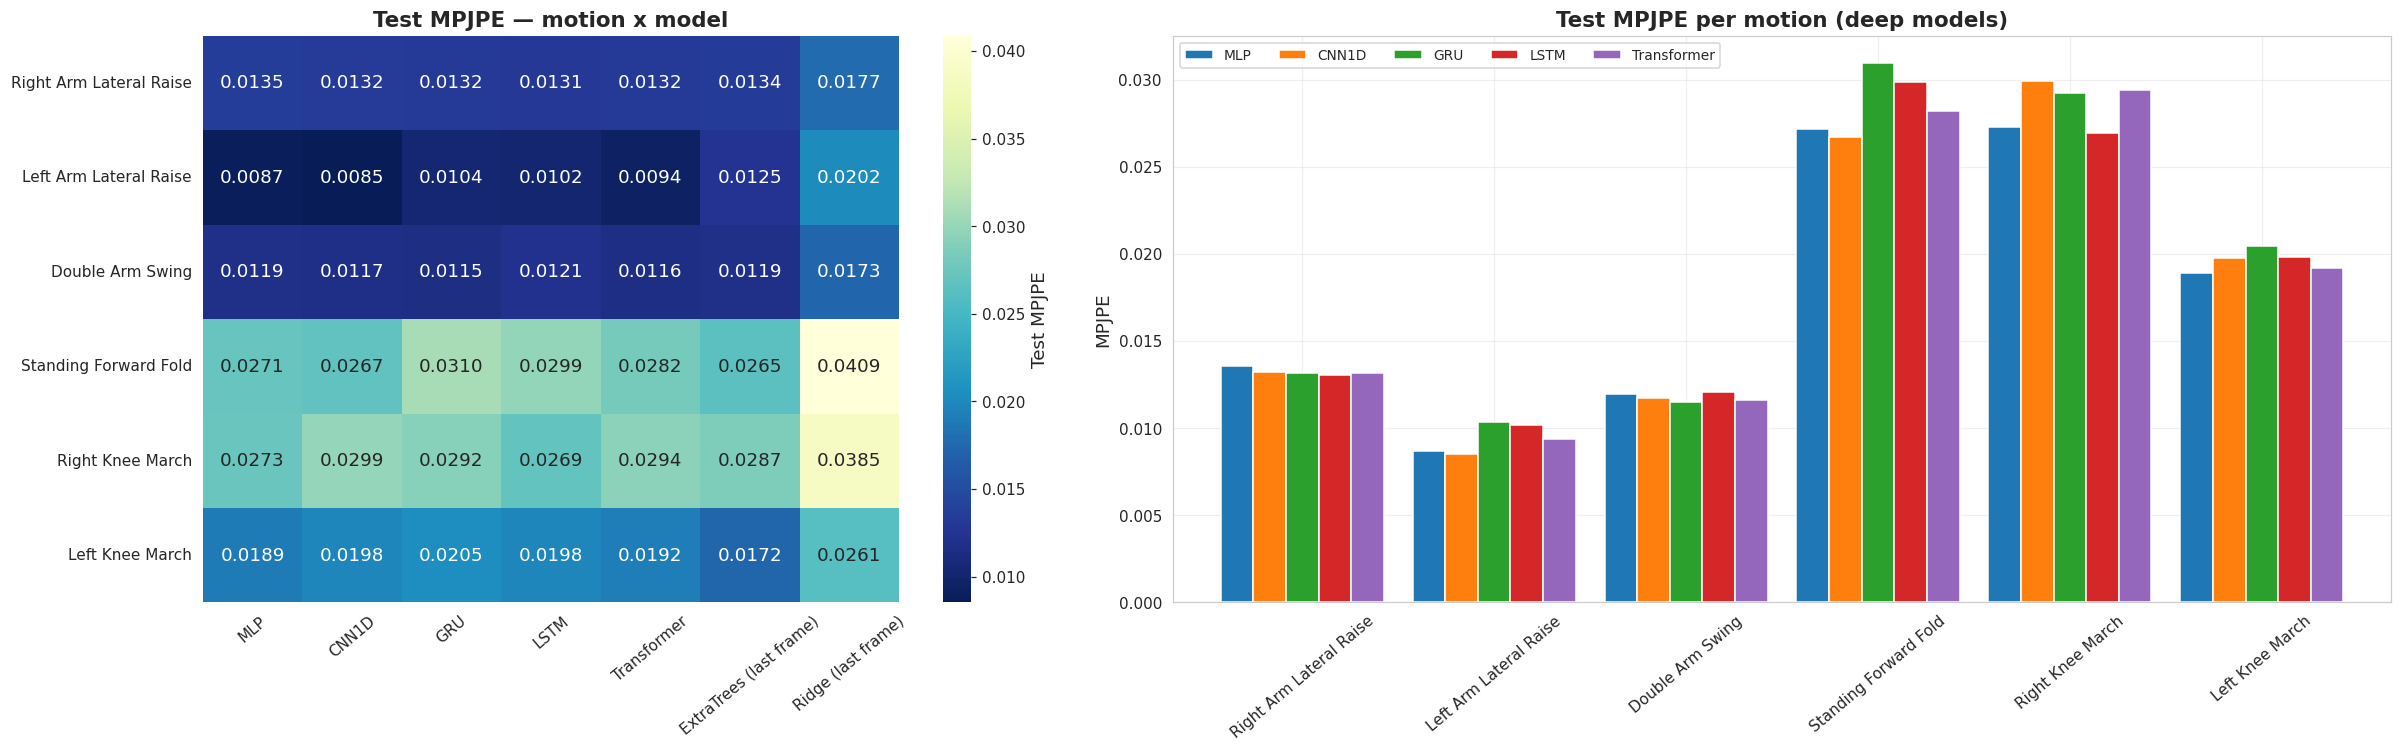

In [24]:
# Figures: MPJPE heatmap + grouped bars
fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(mpjpe_matrix, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0], cbar_kws={"label": "Test MPJPE"})
axes[0].set_title("Test MPJPE — motion x model"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=40)

mpjpe_matrix[deep_cols].plot(kind="bar", ax=axes[1], width=0.85)
axes[1].set_title("Test MPJPE per motion (deep models)"); axes[1].set_ylabel("MPJPE"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=40); axes[1].legend(ncol=5, fontsize=9)
plt.tight_layout(); savefig("summary_mpjpe_all_motions.png"); plt.show()

# PART C — One model trained on the combined dataset (all 6 motions)

All 6 recordings are merged into **one** training set and the same five architectures are trained once on it.

How the combination respects the time-series structure:

1. Each motion keeps its own block-wise split, so every motion contributes train, validation **and** test frames.
2. The scalers are fit once on the **union of all motions' training rows**.
3. Sliding windows are built **per motion, per contiguous segment**, then concatenated. No window mixes frames
   from two motions or from two blocks.
4. The test windows are the same frames as in Part A, so the combined model can be compared with the
   single-motion models motion by motion. A `motion_id` is kept for every window for this breakdown
   (it is **not** an input to the model, the model only sees IMU data).
5. Per-motion metrics of the combined model use that motion's own train mean as the R² OOS benchmark and its own
   active-column set, so they are comparable with Part A (the pooled numbers use the all-motion train statistics).
6. The combined model does **pose regression for all 6 motions with one set of weights**. It is not told which motion
   is being performed and it does not output a motion label.


In [25]:
# ---- global scalers (training rows of all motions) ----
X_train_rows = np.concatenate([d["X_raw"][train_row_indices(d["segments"])] for d in MOTION_DATA.values()])
Y_train_rows = np.concatenate([d["Y_raw"][train_row_indices(d["segments"])] for d in MOTION_DATA.values()])
imu_scaler_all, pose_scaler_all = fit_scalers(X_train_rows, Y_train_rows)
joblib.dump(imu_scaler_all,  os.path.join(DIR_SCALERS, "ALL_imu_scaler.joblib"))
joblib.dump(pose_scaler_all, os.path.join(DIR_SCALERS, "ALL_pose_scaler.joblib"))

# ---- windows per motion, then concatenate (keep motion id for the per-motion breakdown) ----
buf = {s: {"X": [], "Y": [], "id": []} for s in ("train", "val", "test")}
for mi, (m, d) in enumerate(MOTION_DATA.items()):
    dd = split_arrays(scale_imu(imu_scaler_all, d["X_raw"]),
                      pose_scaler_all.transform(d["Y_raw"]).astype("float32"), d["segments"])
    for s in ("train", "val", "test"):
        buf[s]["X"].append(dd[s][0]); buf[s]["Y"].append(dd[s][1])
        buf[s]["id"].append(np.full(len(dd[s][0]), mi, dtype="int32"))

DATA_ALL = {s: (np.concatenate(buf[s]["X"]), np.concatenate(buf[s]["Y"])) for s in buf}
IDS_ALL  = {s: np.concatenate(buf[s]["id"]) for s in buf}

for s in ("train", "val", "test"):
    print(f"{s:5s}: X {DATA_ALL[s][0].shape}  Y {DATA_ALL[s][1].shape}")
assert not np.isnan(DATA_ALL["train"][0]).any() and not np.isnan(DATA_ALL["train"][1]).any()

per_motion_counts = pd.DataFrame({s: np.bincount(IDS_ALL[s], minlength=len(MOTIONS)) for s in ("train", "val", "test")},
                                 index=MOTIONS)
display(per_motion_counts)

# window boundaries inside the pooled test set (block seams and motion boundaries), for plots
TEST_BOUNDS = np.cumsum([w for d in MOTION_DATA.values() for w in test_seg_windows(d["segments"])])[:-1]
assert (TEST_BOUNDS < len(DATA_ALL["test"][0])).all()

# per-motion benchmark mean and active columns from each motion's OWN training rows (same as Part A)
PM_STATS = {}
for m, d in MOTION_DATA.items():
    yr = d["Y_raw"][train_row_indices(d["segments"])].astype("float64")
    PM_STATS[m] = dict(mean=yr.mean(axis=0), active=active_mask_from(yr.var(axis=0)))


train: X (12073, 10, 30)  Y (12073, 51)
val  : X (2780, 10, 30)  Y (2780, 51)
test : X (2843, 10, 30)  Y (2843, 51)


,train,val,test
Right Arm Lateral Raise,2080,480,491
Left Arm Lateral Raise,2092,484,494
Double Arm Swing,1838,420,430
Standing Forward Fold,2268,528,538
Right Knee March,1871,428,438
Left Knee March,1924,440,452


### C.1 Train the five models on the whole dataset

In [26]:
all_models, all_hist, all_time = {}, {}, {}
for mn, builder in MODEL_BUILDERS.items():
    print("\n" + "=" * 70); print(f"Training {mn} on ALL 6 motions ({N_SEEDS_COMBINED} seeds)"); print("=" * 70)
    ens, hist, secs = train_ensemble(mn, builder, DATA_ALL, pose_scaler_all, N_SEEDS_COMBINED,
                                     BATCH_SIZE_COMBINED, "ALL", use_ckpt=True)
    all_models[mn], all_hist[mn], all_time[mn] = ens, hist, secs
    print(f"{mn}: total training time {secs:.1f} s")

with open(os.path.join(DIR_RESULTS, "combined_training_history.json"), "w") as f:
    json.dump(all_hist, f)


Training MLP on ALL 6 motions (3 seeds)
    MLP         seed 0: 137 epochs | best  97 | train 0.0606 | val 0.0383
    MLP         seed 1: 152 epochs | best 112 | train 0.0587 | val 0.0387
    MLP         seed 2: 160 epochs | best 120 | train 0.0589 | val 0.0386
MLP: total training time 290.3 s

Training CNN1D on ALL 6 motions (3 seeds)
    CNN1D       seed 0: 176 epochs | best 136 | train 0.0561 | val 0.0368
    CNN1D       seed 1: 136 epochs | best  96 | train 0.0581 | val 0.0370
    CNN1D       seed 2: 129 epochs | best  94 | train 0.0575 | val 0.0371
CNN1D: total training time 387.1 s

Training GRU on ALL 6 motions (3 seeds)
    GRU         seed 0:  92 epochs | best  52 | train 0.0449 | val 0.0312
    GRU         seed 1: 130 epochs | best  90 | train 0.0423 | val 0.0310
    GRU         seed 2:  95 epochs | best  55 | train 0.0438 | val 0.0316
GRU: total training time 486.0 s

Training LSTM on ALL 6 motions (3 seeds)
    LSTM        seed 0:  73 epochs | best  33 | train 0.0453 | val

### C.2 Evaluate on the pooled test set (all motions) and compare with reference baselines

In [27]:
COMB, comb_rows = {}, []
for mn, ens in all_models.items():
    tr, va, te, inf, fps = evaluate_all_splits(ens, DATA_ALL, pose_scaler_all)
    COMB[mn] = dict(train=tr, val=va, test=te, n_params=ens.count_params(), training_time=all_time[mn],
                    inference_time=inf, fps=fps)
    comb_rows.append(make_row("ALL (combined)", mn, "deep", tr, va, te, ens.count_params(), all_time[mn], fps))
    print(f"{mn:12s} | Test MAE {te['mae']:.5f} | RMSE {te['rmse']:.5f} | MPJPE {te['mpjpe']:.5f} | "
          f"R2 {te['r2']:.4f} | R2 OOS {te['r2_oos']:.4f} | R2 active {te['r2_active']:.4f} | {fps:.0f} FPS")

REF_COMB = {}
for rn, rm in make_reference_models().items():
    t0 = time.time(); rm.fit(*DATA_ALL["train"]); secs = time.time() - t0
    tr, va, te, inf, fps = evaluate_all_splits(rm, DATA_ALL, pose_scaler_all)
    REF_COMB[rn] = dict(test=te)
    comb_rows.append(make_row("ALL (combined)", rn, "reference", tr, va, te, 0, secs, fps))

comb_df = pd.DataFrame(comb_rows).sort_values(["Type", "Test_MPJPE"]).reset_index(drop=True)
comb_df.to_csv(os.path.join(DIR_RESULTS, "combined_model_comparison.csv"), index=False)

best_comb = comb_df[comb_df.Type == "deep"].sort_values("Val_MPJPE").iloc[0]["Model"]   # selected on VALIDATION MPJPE
const_mpjpe = mpjpe(pose_scaler_all.inverse_transform(DATA_ALL["test"][1]),
                    np.tile(pose_scaler_all.mean_, (len(DATA_ALL["test"][1]), 1)))[0]
print(f"\nBest combined model (lowest pooled validation MPJPE): {best_comb}")
print(f"Constant train-mean baseline MPJPE on the pooled test set: {const_mpjpe:.5f}")
display(comb_df.style.format({c: "{:.5f}" for c in ["Train_MPJPE", "Val_MPJPE", "Test_MAE", "Test_RMSE", "Test_MPJPE",
                                                   "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                             | {"Test_over_Train": "{:.2f}", "Params": "{:,}"})
        .highlight_min(subset=["Test_MPJPE", "Test_MAE", "Test_RMSE"], color="lightgreen").hide(axis="index"))

MLP          | Test MAE 0.01311 | RMSE 0.03512 | MPJPE 0.02781 | R2 0.8574 | R2 OOS 0.8612 | R2 active 0.8262 | 4410 FPS
CNN1D        | Test MAE 0.01274 | RMSE 0.03482 | MPJPE 0.02696 | R2 0.8598 | R2 OOS 0.8636 | R2 active 0.8282 | 3697 FPS
GRU          | Test MAE 0.01212 | RMSE 0.03487 | MPJPE 0.02565 | R2 0.8594 | R2 OOS 0.8632 | R2 active 0.8276 | 3101 FPS
LSTM         | Test MAE 0.01200 | RMSE 0.03411 | MPJPE 0.02532 | R2 0.8655 | R2 OOS 0.8691 | R2 active 0.8327 | 2740 FPS
Transformer  | Test MAE 0.01183 | RMSE 0.03344 | MPJPE 0.02494 | R2 0.8707 | R2 OOS 0.8742 | R2 active 0.8392 | 2420 FPS

Best combined model (lowest pooled validation MPJPE): Transformer
Constant train-mean baseline MPJPE on the pooled test set: 0.13241


Motion,Model,Type,Params,TrainTime_s,FPS,Train_MPJPE,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Test_over_Train
ALL (combined),Transformer,deep,"17,011",1049.600000,2419.700000,0.02204,0.02664,0.01183,0.03344,0.02494,0.87070,0.87415,0.83915,1.13
ALL (combined),LSTM,deep,"34,835",349.340000,2740.200000,0.02258,0.02692,0.01200,0.03411,0.02532,0.86550,0.86910,0.83267,1.12
ALL (combined),GRU,deep,"28,947",486.020000,3100.800000,0.02239,0.02686,0.01212,0.03487,0.02565,0.85941,0.86317,0.82762,1.15
ALL (combined),CNN1D,deep,"20,691",387.140000,3697.400000,0.02466,0.02889,0.01274,0.03482,0.02696,0.85984,0.86359,0.82820,1.09
ALL (combined),MLP,deep,"50,099",290.350000,4410.300000,0.02484,0.03021,0.01311,0.03512,0.02781,0.85741,0.86122,0.82625,1.12
ALL (combined),ExtraTrees (last frame),reference,0,10.510000,16577.300000,0.01742,0.02872,0.01194,0.03365,0.02539,0.86904,0.87254,0.83863,1.46
ALL (combined),Ridge (last frame),reference,0,0.010000,2732960.100000,0.09092,0.09391,0.04653,0.06857,0.09747,0.45638,0.47090,0.43351,1.07


### C.3 Combined-model results broken down per motion

TABLE C1: COMBINED MODELS — Test MPJPE on each motion (green = best in row)


Model,MLP,CNN1D,GRU,LSTM,Transformer
Motion,,,,,
Right Arm Lateral Raise,0.01824,0.01835,0.01649,0.01662,0.01572
Left Arm Lateral Raise,0.01664,0.01599,0.01435,0.01376,0.01497
Double Arm Swing,0.01828,0.01746,0.01627,0.01652,0.01573
Standing Forward Fold,0.03001,0.02991,0.02871,0.02937,0.02758
Right Knee March,0.05943,0.05732,0.05658,0.05437,0.05466
Left Knee March,0.02622,0.02442,0.02327,0.02280,0.02264


Saved figure -> figures/combined_mpjpe_per_motion.png


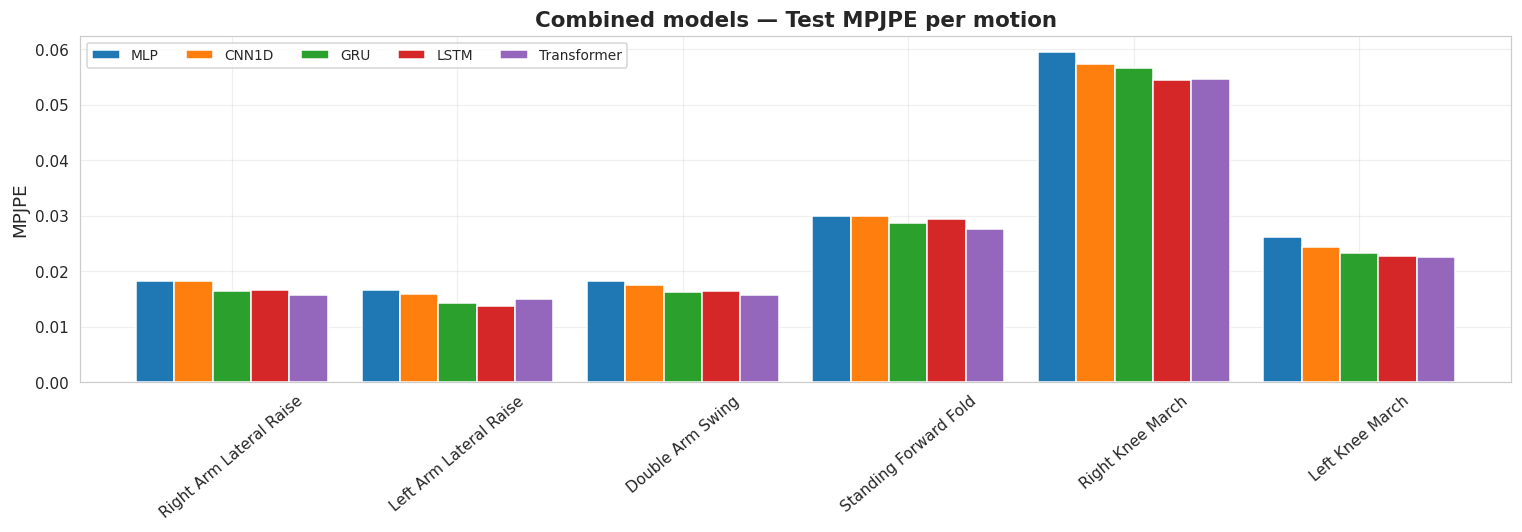

In [28]:
# Metrics of every combined model on the test windows of each motion (same frames as in Part A)
rows = []
for mn in MODEL_BUILDERS:
    yt, yp = COMB[mn]["test"]["y_true"], COMB[mn]["test"]["y_pred"]
    for mi, m in enumerate(MOTIONS):
        mask = IDS_ALL["test"] == mi
        mm = compute_metrics(yt[mask], yp[mask], pose_scaler_all,
                             bench_mean=PM_STATS[m]["mean"], active_mask=PM_STATS[m]["active"])
        rows.append(dict(Motion=m, Model=mn, MAE=mm["mae"], RMSE=mm["rmse"], MPJPE=mm["mpjpe"],
                         R2=mm["r2"], R2_OOS=mm["r2_oos"], R2_active=mm["r2_active"]))
comb_per_motion = pd.DataFrame(rows)
comb_per_motion.to_csv(os.path.join(DIR_RESULTS, "combined_model_per_motion.csv"), index=False)

pm_mpjpe = comb_per_motion.pivot(index="Motion", columns="Model", values="MPJPE").loc[MOTIONS][list(MODEL_BUILDERS)]
print("TABLE C1: COMBINED MODELS — Test MPJPE on each motion (green = best in row)")
display(pm_mpjpe.style.format("{:.5f}").highlight_min(axis=1, color="lightgreen"))

fig, ax = plt.subplots(figsize=(14, 5))
pm_mpjpe.plot(kind="bar", ax=ax, width=0.85)
ax.set_title("Combined models — Test MPJPE per motion"); ax.set_ylabel("MPJPE"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=40); ax.legend(ncol=5, fontsize=9)
plt.tight_layout(); savefig("combined_mpjpe_per_motion.png"); plt.show()

In [29]:
# Single-motion models (Part A) vs the ONE combined model (Part C), same test frames
best_single = table2.set_index("Motion")[["Model", "Test_MPJPE", "Test_R2_OOS"]].rename(
    columns={"Model": "Best_single_model", "Test_MPJPE": "Single_MPJPE", "Test_R2_OOS": "Single_R2_OOS"})
same_arch = mpjpe_matrix[best_comb].rename("Single_same_arch_MPJPE")      # Part A, same architecture as the combined model
cp = comb_per_motion[comb_per_motion.Model == best_comb].set_index("Motion")[["MPJPE", "R2_OOS"]].rename(
    columns={"MPJPE": "Combined_MPJPE", "R2_OOS": "Combined_R2_OOS"})
vs = best_single.join(cp).join(same_arch).loc[MOTIONS].reset_index()
vs["MPJPE_change_%"] = 100 * (vs["Combined_MPJPE"] - vs["Single_MPJPE"]) / vs["Single_MPJPE"]
vs["Change_vs_same_arch_%"] = 100 * (vs["Combined_MPJPE"] - vs["Single_same_arch_MPJPE"]) / vs["Single_same_arch_MPJPE"]
vs["Better"] = np.where(vs["Combined_MPJPE"] < vs["Single_MPJPE"], "combined", "single-motion")
mean_row = {"Motion": "MEAN", "Best_single_model": "-",
            "Single_MPJPE": vs.Single_MPJPE.mean(), "Single_R2_OOS": vs.Single_R2_OOS.mean(),
            "Combined_MPJPE": vs.Combined_MPJPE.mean(), "Combined_R2_OOS": vs.Combined_R2_OOS.mean(),
            "Single_same_arch_MPJPE": vs.Single_same_arch_MPJPE.mean(),
            "MPJPE_change_%": 100 * (vs.Combined_MPJPE.mean() - vs.Single_MPJPE.mean()) / vs.Single_MPJPE.mean(),
            "Change_vs_same_arch_%": 100 * (vs.Combined_MPJPE.mean() - vs.Single_same_arch_MPJPE.mean()) / vs.Single_same_arch_MPJPE.mean(),
            "Better": "-"}
vs = pd.concat([vs, pd.DataFrame([mean_row])], ignore_index=True)
vs.to_csv(os.path.join(DIR_RESULTS, "single_vs_combined.csv"), index=False)
print(f"TABLE C2: BEST SINGLE-MOTION MODEL (chosen on val) and SAME-ARCHITECTURE single model vs COMBINED {best_comb} "
      "(negative change = combined is better)")
display(vs.style.format({"Single_MPJPE": "{:.5f}", "Combined_MPJPE": "{:.5f}", "Single_same_arch_MPJPE": "{:.5f}",
                         "Single_R2_OOS": "{:.4f}", "Combined_R2_OOS": "{:.4f}",
                         "MPJPE_change_%": "{:+.1f}%", "Change_vs_same_arch_%": "{:+.1f}%"}).hide(axis="index"))
if N_SEEDS_MOTION != N_SEEDS_COMBINED:
    print(f"NOTE: single-motion models average {N_SEEDS_MOTION} seed(s), combined models {N_SEEDS_COMBINED}. "
          "Part of any gap comes from ensembling, not from more data. "
          "Set N_SEEDS_MOTION = N_SEEDS_COMBINED for a like-for-like comparison.")


TABLE C2: BEST SINGLE-MOTION MODEL (chosen on val) and SAME-ARCHITECTURE single model vs COMBINED Transformer (negative change = combined is better)


Motion,Best_single_model,Single_MPJPE,Single_R2_OOS,Combined_MPJPE,Combined_R2_OOS,Single_same_arch_MPJPE,MPJPE_change_%,Change_vs_same_arch_%,Better
Right Arm Lateral Raise,LSTM,0.01306,0.7615,0.01572,0.7546,0.01316,+20.4%,+19.5%,single-motion
Left Arm Lateral Raise,Transformer,0.00939,0.9440,0.01497,0.9061,0.00939,+59.5%,+59.5%,single-motion
Double Arm Swing,CNN1D,0.01170,0.8951,0.01573,0.8821,0.01162,+34.4%,+35.3%,single-motion
Standing Forward Fold,GRU,0.03096,0.6199,0.02758,0.8010,0.02821,-10.9%,-2.2%,combined
Right Knee March,LSTM,0.02691,0.7241,0.05466,0.0975,0.02940,+103.2%,+85.9%,single-motion
Left Knee March,Transformer,0.01920,0.8744,0.02264,0.8309,0.01920,+18.0%,+18.0%,single-motion
MEAN,-,0.01853,0.8032,0.02522,0.7120,0.01850,+36.1%,+36.3%,-


NOTE: single-motion models average 1 seed(s), combined models 3. Part of any gap comes from ensembling, not from more data. Set N_SEEDS_MOTION = N_SEEDS_COMBINED for a like-for-like comparison.


### C.4 Visualisation of the combined model

Saved figure -> figures/combined_training_curves.png


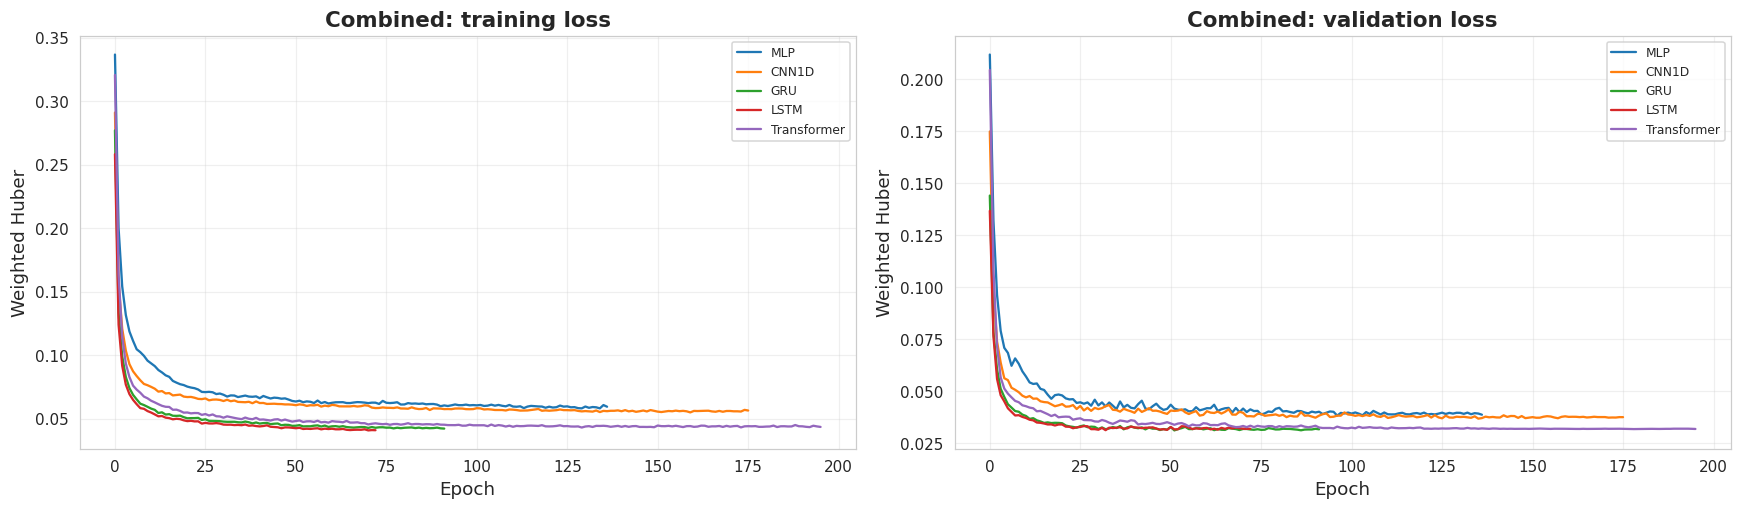

Saved figure -> figures/combined_model_comparison_bars.png


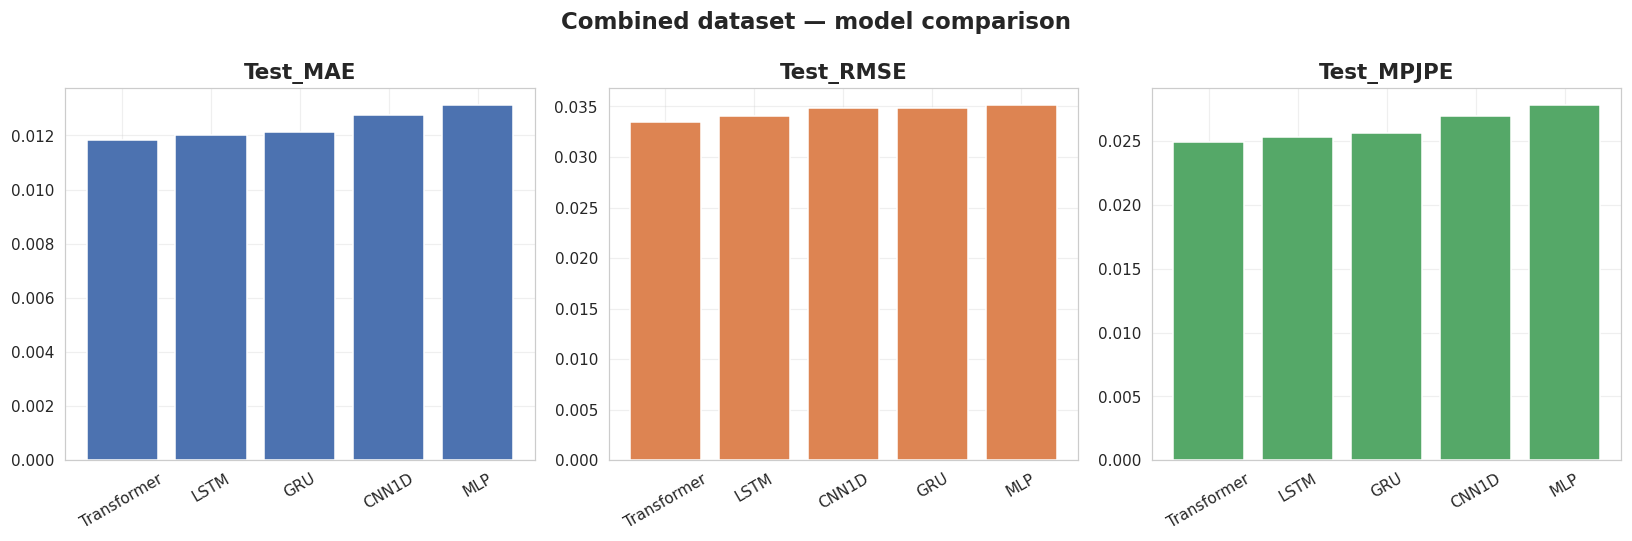

In [30]:
# Loss curves (seed 0) of the five combined models
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for mn, h in all_hist.items():
    axes[0].plot(h["loss"], label=f"{mn}");  axes[1].plot(h["val_loss"], label=f"{mn}")
axes[0].set_title("Combined: training loss"); axes[1].set_title("Combined: validation loss")
for a in axes: a.set_xlabel("Epoch"); a.set_ylabel("Weighted Huber"); a.legend(fontsize=8)
plt.tight_layout(); savefig("combined_training_curves.png"); plt.show()

# Comparison bar charts
cdf = comb_df[comb_df.Type == "deep"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric, color in zip(axes, ["Test_MAE", "Test_RMSE", "Test_MPJPE"], ["#4C72B0", "#DD8452", "#55A868"]):
    o = cdf.sort_values(metric)
    ax.bar(o["Model"], o[metric], color=color); ax.set_title(metric); ax.tick_params(axis="x", rotation=30)
plt.suptitle("Combined dataset — model comparison", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("combined_model_comparison_bars.png"); plt.show()

Saved figure -> figures/combined_pred_vs_true_Transformer.png


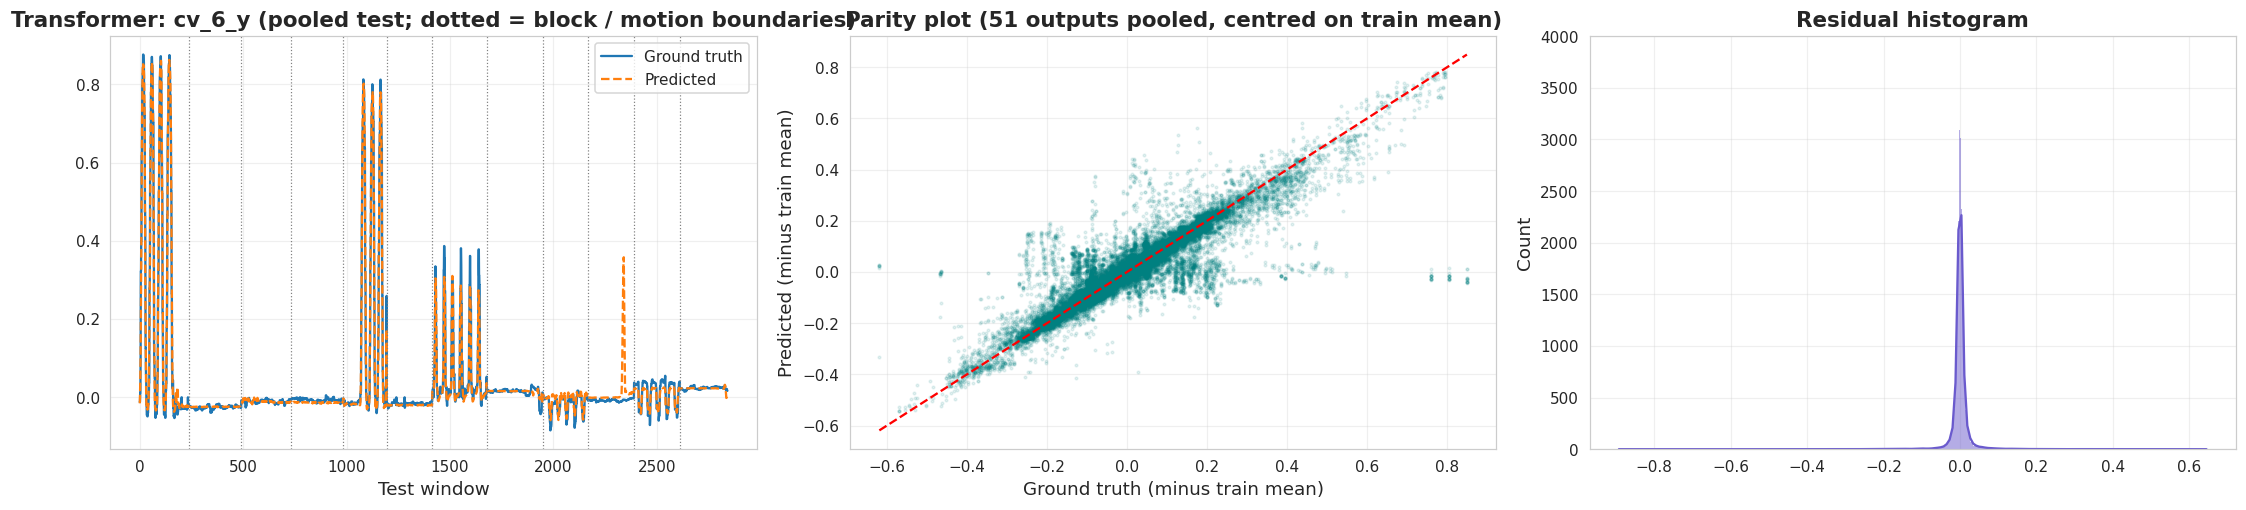

Saved figure -> figures/combined_joint_wise_mpjpe_Transformer.png


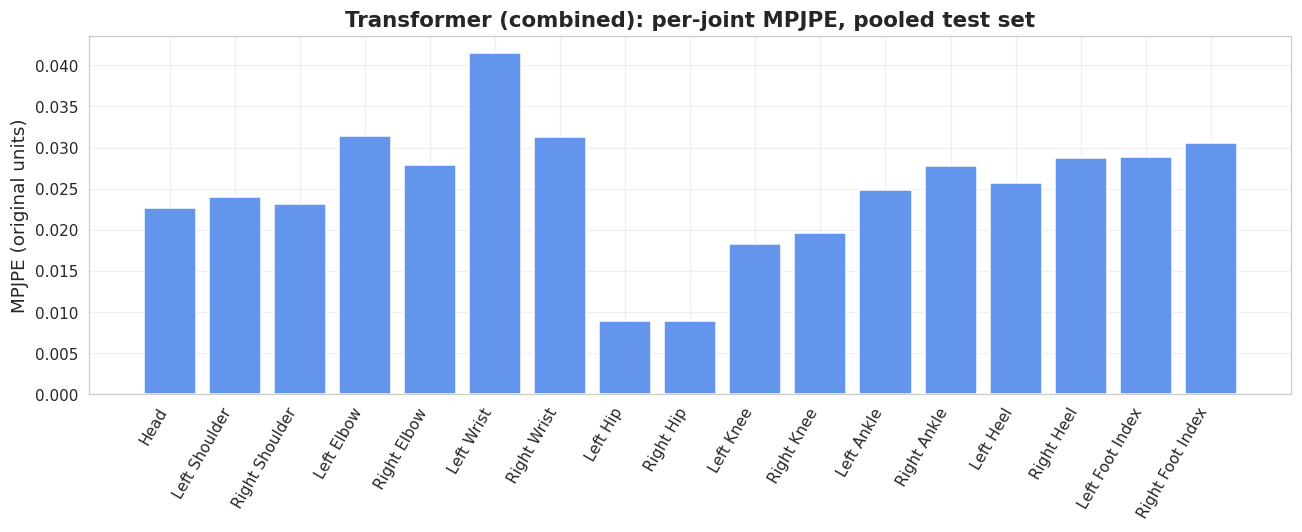

In [31]:
# Predicted vs ground truth, parity and residuals for the best combined model (pooled test set)
yt, yp = COMB[best_comb]["test"]["y_true"], COMB[best_comb]["test"]["y_pred"]
gmean = pose_scaler_all.mean_
j = int(np.argmax(yt.std(axis=0)))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
axes[0].plot(yt[:, j], lw=1.5, label="Ground truth"); axes[0].plot(yp[:, j], "--", lw=1.5, label="Predicted")
for b_ in TEST_BOUNDS:
    axes[0].axvline(b_ - 0.5, color="gray", linestyle=":", lw=0.8)
axes[0].set_title(f"{best_comb}: {pose_cols[j]} (pooled test; dotted = block / motion boundaries)")
axes[0].set_xlabel("Test window"); axes[0].legend()

# parity on values centred by the train mean (otherwise between-joint offsets make any model look perfect)
ytc, ypc = (yt - gmean).flatten(), (yp - gmean).flatten()
axes[1].scatter(ytc, ypc, s=3, alpha=0.1, color="teal")
lim = [min(ytc.min(), ypc.min()), max(ytc.max(), ypc.max())]
axes[1].plot(lim, lim, "r--"); axes[1].set_title("Parity plot (51 outputs pooled, centred on train mean)")
axes[1].set_xlabel("Ground truth (minus train mean)"); axes[1].set_ylabel("Predicted (minus train mean)")
sns.histplot((yp - yt).flatten(), kde=True, ax=axes[2], color="slateblue"); axes[2].set_title("Residual histogram")
plt.tight_layout(); savefig(f"combined_pred_vs_true_{best_comb}.png"); plt.show()

# Per-joint MPJPE
plt.figure(figsize=(12, 5))
plt.bar(KEYPOINT_NAMES, COMB[best_comb]["test"]["per_joint_mpjpe"], color="cornflowerblue")
plt.xticks(rotation=60, ha="right"); plt.ylabel("MPJPE (original units)")
plt.title(f"{best_comb} (combined): per-joint MPJPE, pooled test set")
plt.tight_layout(); savefig(f"combined_joint_wise_mpjpe_{best_comb}.png"); plt.show()


Saved figure -> figures/combined_Transformer_Right_Arm_Lateral_Raise_3x3_skeleton.png


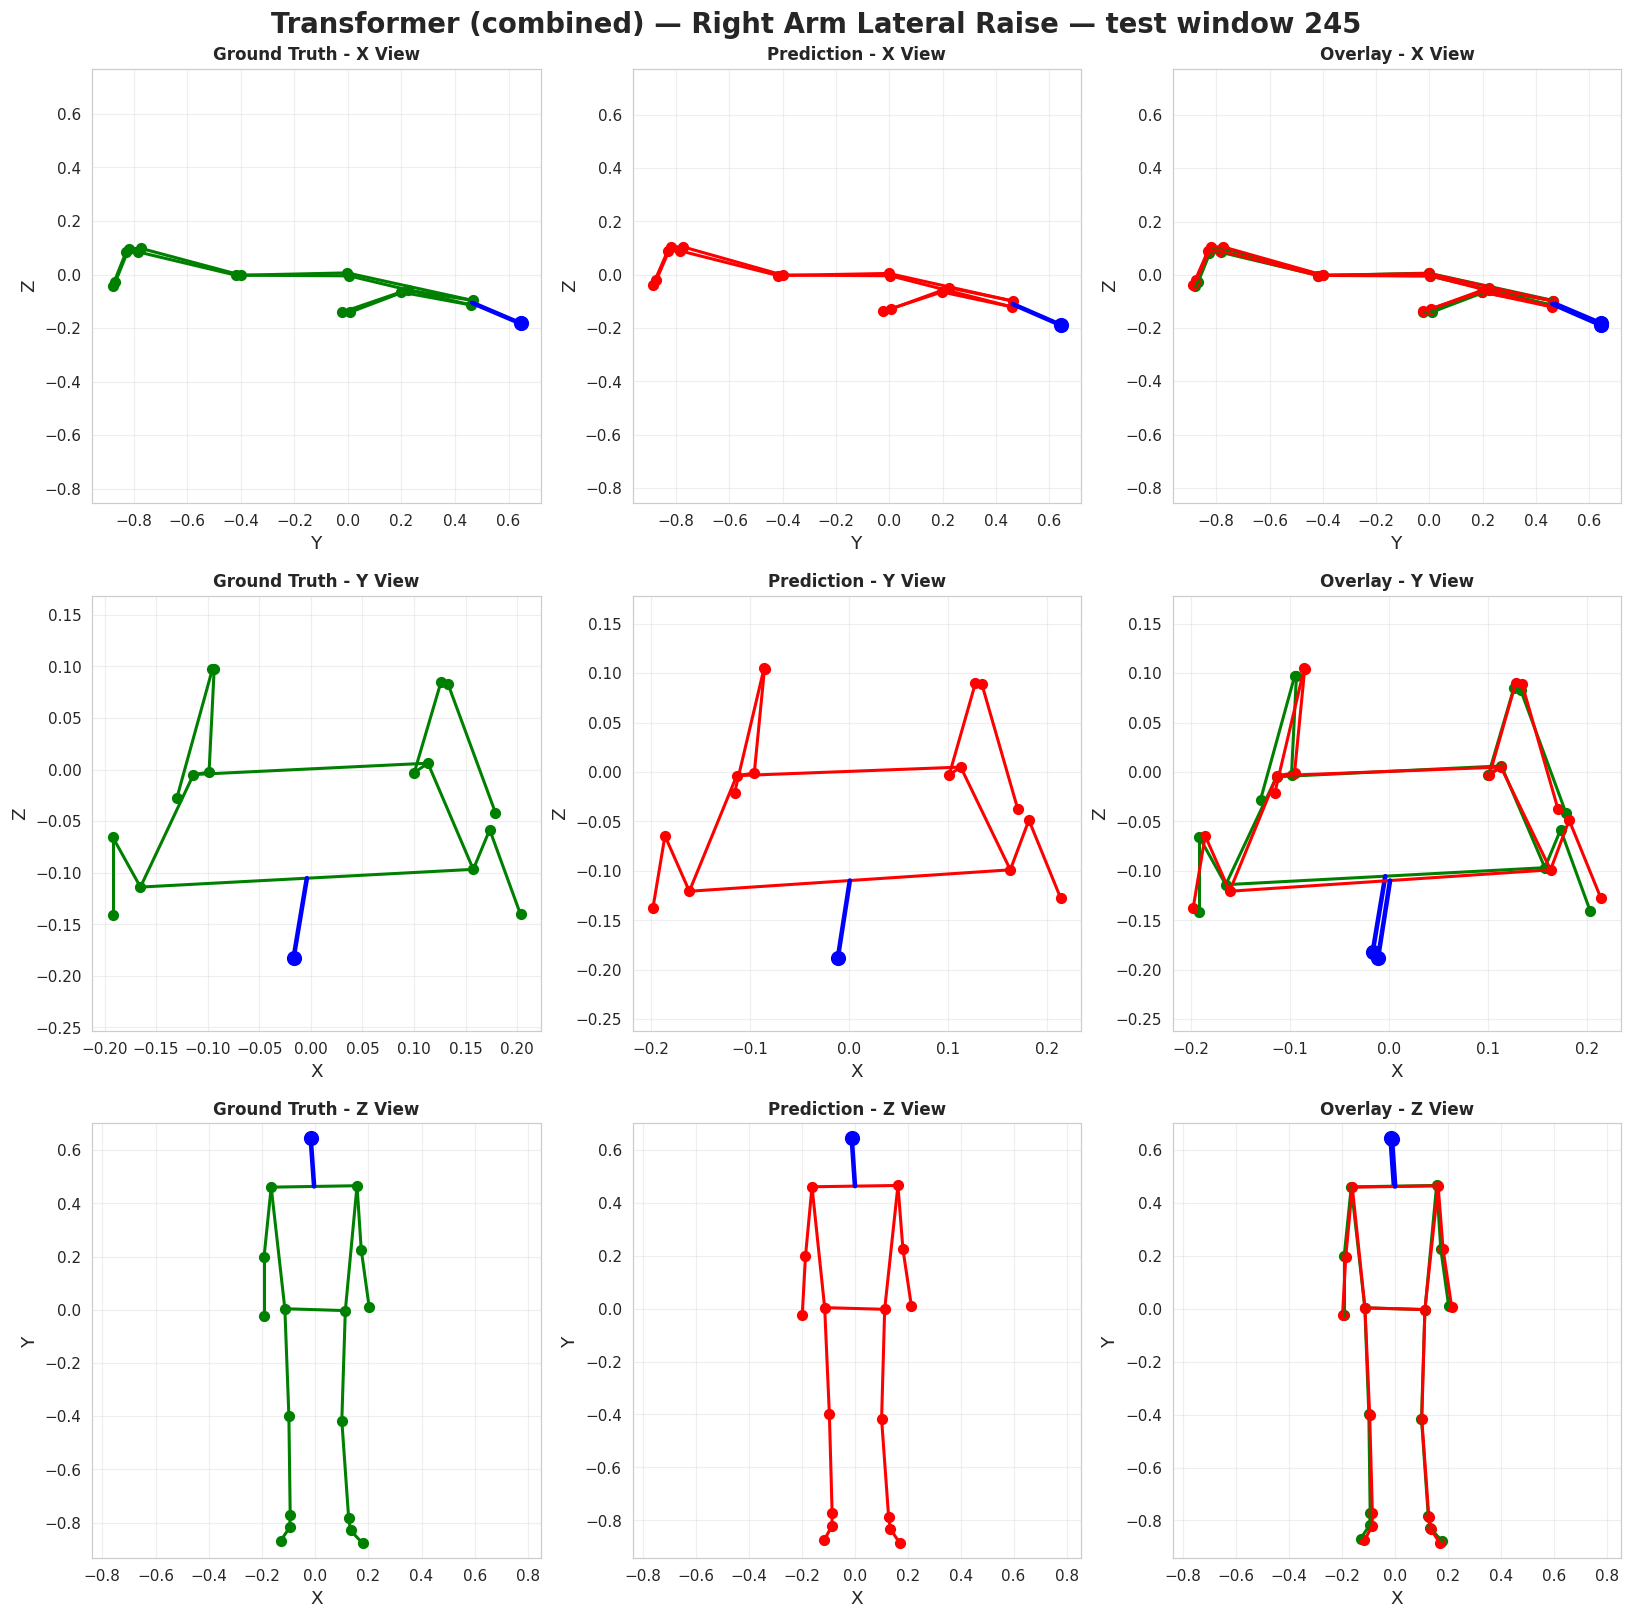

In [32]:
# 3x3 skeleton projection (ground truth / prediction / overlay) for one frame of EVERY motion would be 6 figures;
# here: the middle test frame of one motion. Change SKELETON_MOTION to look at another motion.
SKELETON_MOTION = MOTIONS[0]
mi = MOTIONS.index(SKELETON_MOTION)
idx = np.where(IDS_ALL["test"] == mi)[0]
fi = idx[len(idx) // 2]
plot_skeleton_3x3(yt[fi].reshape(N_JOINTS, 3), yp[fi].reshape(N_JOINTS, 3),
                  f"{best_comb} (combined) — {SKELETON_MOTION} — test window {fi}",
                  f"combined_{best_comb}_{safe_name(SKELETON_MOTION)}_3x3_skeleton.png")

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

Saved animation -> figures/combined_skeleton_animation_Right_Arm_Lateral_Raise_Transformer.gif


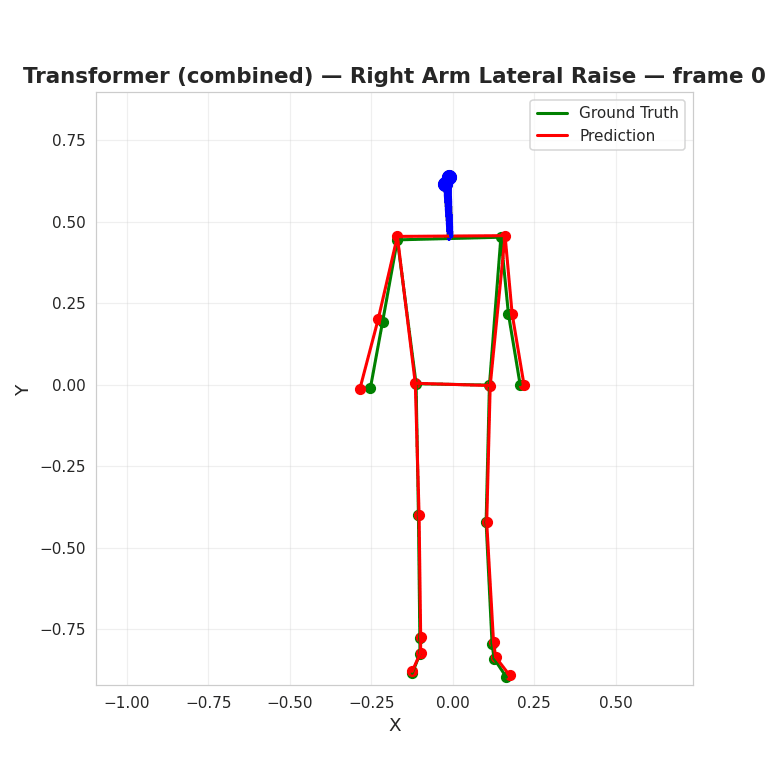

In [33]:
# Animated skeleton (Z view) for the first test windows of ANIM_MOTION
ANIM_MOTION = MOTIONS[0]
# first test segment only, so the animation never jumps across the seam between two test blocks
first_len = test_seg_windows(MOTION_DATA[ANIM_MOTION]["segments"])[0]
idx = np.where(IDS_ALL["test"] == MOTIONS.index(ANIM_MOTION))[0][:min(200, first_len)]
yt_a, yp_a = yt[idx], yp[idx]

fig, ax = plt.subplots(figsize=(7, 7))
pts = np.vstack([yt_a.reshape(-1, 3), yp_a.reshape(-1, 3)])
(xmin, ymin), (xmax, ymax) = pts[:, :2].min(0) - 0.02, pts[:, :2].max(0) + 0.02

def update(f):
    ax.clear()
    plot_projection(ax, yt_a[f].reshape(N_JOINTS, 3), "green", "Z")
    plot_projection(ax, yp_a[f].reshape(N_JOINTS, 3), "red", "Z")
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.set_aspect("equal")
    ax.set_title(f"{best_comb} (combined) — {ANIM_MOTION} — frame {f}")
    ax.plot([], [], color="green", lw=2, label="Ground Truth"); ax.plot([], [], color="red", lw=2, label="Prediction")
    ax.legend(loc="upper right")

anim = animation.FuncAnimation(fig, update, frames=len(idx), interval=50)      # 20 Hz = real time
anim_path = os.path.join(DIR_FIGURES, f"combined_skeleton_animation_{safe_name(ANIM_MOTION)}_{best_comb}.gif")
anim.save(anim_path, writer=animation.PillowWriter(fps=20))
plt.close(fig)
print("Saved animation ->", anim_path)
display(Image(filename=anim_path))

### C.5 Explainability: permutation importance of the 30 IMU channels (best combined model)

Saved figure -> figures/combined_permutation_importance.png


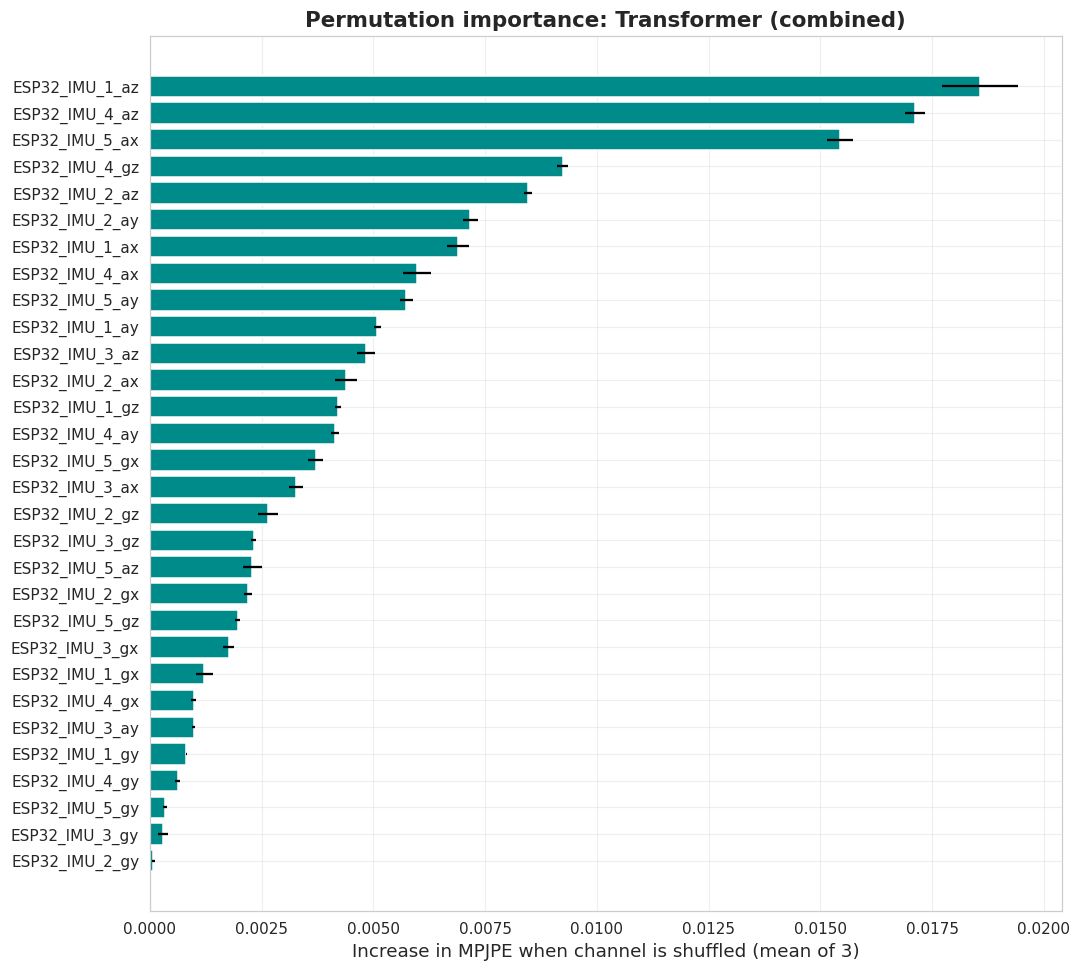

,IMU Channel,MPJPE Increase,Std
0,ESP32_IMU_1_az,0.018578,0.000852
1,ESP32_IMU_4_az,0.017122,0.000219
2,ESP32_IMU_5_ax,0.015444,0.000296
3,ESP32_IMU_4_gz,0.009238,0.000126
4,ESP32_IMU_2_az,0.008454,0.000086


In [34]:
best_model = all_models[best_comb]
X_te = DATA_ALL["test"][0]
y_true_c = COMB[best_comb]["test"]["y_true"]
base_mpjpe = COMB[best_comb]["test"]["mpjpe"]

N_REPEATS = 3
rng = np.random.default_rng(SEED)
imp, imp_std = [], []
for fi_, fn in enumerate(imu_cols):
    deltas = []
    for _ in range(N_REPEATS):
        Xs = X_te.copy()
        Xs[:, :, fi_] = X_te[rng.permutation(len(X_te)), :, fi_]          # shuffle across test windows
        deltas.append(mpjpe(y_true_c, predict_orig(best_model, Xs, pose_scaler_all))[0] - base_mpjpe)
    imp.append(np.mean(deltas)); imp_std.append(np.std(deltas))

importance_df = pd.DataFrame({"IMU Channel": imu_cols, "MPJPE Increase": imp, "Std": imp_std}).sort_values(
    "MPJPE Increase", ascending=False).reset_index(drop=True)
importance_df.to_csv(os.path.join(DIR_RESULTS, "combined_permutation_importance.csv"), index=False)

plt.figure(figsize=(10, 9))
plt.barh(importance_df["IMU Channel"], importance_df["MPJPE Increase"], xerr=importance_df["Std"], color="darkcyan")
plt.gca().invert_yaxis(); plt.xlabel(f"Increase in MPJPE when channel is shuffled (mean of {N_REPEATS})")
plt.title(f"Permutation importance: {best_comb} (combined)")
plt.tight_layout(); savefig("combined_permutation_importance.png"); plt.show()
display(importance_df.head(5))


### C.6 Save combined artifacts and inference function

In [35]:
best_model.save(os.path.join(DIR_MODELS, "ALL_best_model_overall.keras"))   # writes ALL_best_model_overall_member{i}.keras
with open(os.path.join(DIR_RESULTS, "inference_config.json"), "w") as f:
    json.dump(dict(best_model=best_comb, window_size=WINDOW_SIZE, n_members=len(best_model.members),
                   split_mode=SPLIT_MODE, imu_cols=imu_cols, pose_cols=pose_cols, motions=MOTIONS), f, indent=2)
for mn, r in COMB.items():
    np.save(os.path.join(DIR_RESULTS, f"ALL_y_pred_test_{mn}.npy"), r["test"]["y_pred"])
np.save(os.path.join(DIR_RESULTS, "ALL_y_true_test.npy"), COMB[best_comb]["test"]["y_true"])
np.save(os.path.join(DIR_RESULTS, "ALL_test_motion_ids.npy"), IDS_ALL["test"])
with open(os.path.join(DIR_RESULTS, "motion_names.json"), "w") as f:
    json.dump(MOTIONS, f)
print("Saved combined model, scalers, predictions and tables in:", DIR_MODELS, DIR_SCALERS, DIR_RESULTS)


def predict_pose_from_imu(imu_window_df, model=None, imu_scaler=imu_scaler_all, pose_scaler=pose_scaler_all,
                          imu_columns=imu_cols, pose_columns=pose_cols, model_path=None):
    """imu_window_df: DataFrame with the 30 IMU columns and WINDOW_SIZE rows (oldest -> newest)."""
    if model is None:
        model = EnsembleModel.load(model_path)       # model_path e.g. "saved_models/ALL_best_model_overall.keras"
    X_new = imu_window_df[imu_columns].values.astype("float32")
    assert X_new.shape[0] == WINDOW_SIZE, f"Expected {WINDOW_SIZE} rows, got {X_new.shape[0]}"
    y = model.predict(scale_imu(imu_scaler, X_new)[None, ...], verbose=0)
    return pd.Series(pose_scaler.inverse_transform(y)[0], index=pose_columns)

# Demo: first test window of the first motion
seg_start = next(s for nm, s, e in MOTION_DATA[MOTIONS[0]]["segments"] if nm == "test")
demo = pd.DataFrame(MOTION_DATA[MOTIONS[0]]["X_raw"][seg_start:seg_start + WINDOW_SIZE], columns=imu_cols)
display(predict_pose_from_imu(demo, model=best_model).to_frame("predicted_value").T)
seg_true = MOTION_DATA[MOTIONS[0]]["Y_raw"][seg_start + WINDOW_SIZE - 1]
demo_pred = predict_pose_from_imu(demo, model=best_model).values
print(f"Demo MPJPE vs ground truth at the window's last frame: "
      f"{np.linalg.norm((demo_pred - seg_true).reshape(-1, 3), axis=1).mean():.5f}")


Saved combined model, scalers, predictions and tables in: saved_models saved_scalers results


,cv_0_x,cv_0_y,cv_0_z,cv_1_x,cv_1_y,cv_1_z,cv_2_x,cv_2_y,cv_2_z,cv_3_x,cv_3_y,cv_3_z,cv_4_x,cv_4_y,cv_4_z,cv_5_x,cv_5_y,cv_5_z,cv_6_x,cv_6_y,cv_6_z,cv_7_x,cv_7_y,cv_7_z,cv_8_x,...,cv_8_z,cv_9_x,cv_9_y,cv_9_z,cv_10_x,cv_10_y,cv_10_z,cv_11_x,cv_11_y,cv_11_z,cv_12_x,cv_12_y,cv_12_z,cv_13_x,cv_13_y,cv_13_z,cv_14_x,cv_14_y,cv_14_z,cv_15_x,cv_15_y,cv_15_z,cv_16_x,cv_16_y,cv_16_z
predicted_value,-0.011693,0.635899,-0.217893,0.160352,0.456589,-0.118595,-0.170066,0.454234,-0.146276,0.181991,0.217034,-0.069213,-0.22891,0.200116,-0.08652,0.218598,-0.001912,-0.154949,-0.285512,-0.015269,-0.159211,0.114744,-0.003119,0.009283,-0.115004,...,-0.007986,0.10406,-0.42261,-0.001145,-0.103372,-0.40016,-0.008705,0.124992,-0.790552,0.091049,-0.098488,-0.774792,0.095251,0.131521,-0.836133,0.089675,-0.098766,-0.82224,0.095613,0.174261,-0.892083,-0.03568,-0.124669,-0.88004,-0.032206


Demo MPJPE vs ground truth at the window's last frame: 0.01418


# FINAL SUMMARY

In [36]:
print("=" * 78)
print("   FINAL SUMMARY — 6 MOTIONS: PER-MOTION MODELS vs ONE COMBINED MODEL")
print("=" * 78)

print("\n[1] Best single-motion model per motion (Part A)")
display(table2[["Motion", "Model", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS"]]
        .style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS"]})
        .hide(axis="index"))

print("\n[2] Average of each architecture over the 6 motions (Part B)")
display(avg[["Mean_MAE", "Mean_RMSE", "Mean_MPJPE", "Mean_R2_OOS", "Mean_rank_among_deep", "Wins (best of 5 deep)"]]
        .style.format("{:.5f}", subset=["Mean_MAE", "Mean_RMSE", "Mean_MPJPE", "Mean_R2_OOS"])
        .format("{:.2f}", subset=["Mean_rank_among_deep"]))

print("\n[3] Models trained on the combined dataset — pooled test set (Part C)")
display(comb_df[comb_df.Type == "deep"][["Model", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS",
                                         "Test_R2_active", "FPS", "Params"]]
        .style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                      | {"Params": "{:,}", "FPS": "{:.1f}"}).hide(axis="index"))

b = comb_df[comb_df.Model == best_comb].iloc[0]
print("\n" + "=" * 78)
print(f"BEST COMBINED MODEL (selected on validation MPJPE): {best_comb}")
print(f"  Test MAE {b.Test_MAE:.5f} | RMSE {b.Test_RMSE:.5f} | MPJPE {b.Test_MPJPE:.5f}")
print(f"  R2 (var-weighted) {b.Test_R2:.4f} | R2 OOS {b.Test_R2_OOS:.4f} | R2 active {b.Test_R2_active:.4f}")
print(f"  mean single-motion MPJPE {vs.iloc[-1].Single_MPJPE:.5f}  vs  combined {vs.iloc[-1].Combined_MPJPE:.5f} "
      f"({vs.iloc[-1]['MPJPE_change_%']:+.1f}%)")
print("=" * 78)

   FINAL SUMMARY — 6 MOTIONS: PER-MOTION MODELS vs ONE COMBINED MODEL

[1] Best single-motion model per motion (Part A)


Motion,Model,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS
Right Arm Lateral Raise,LSTM,0.00606,0.03172,0.01306,0.72413,0.76148
Left Arm Lateral Raise,Transformer,0.00453,0.01243,0.00939,0.79766,0.94404
Double Arm Swing,CNN1D,0.00553,0.02510,0.01170,0.84322,0.89515
Standing Forward Fold,GRU,0.01482,0.03995,0.03096,0.61637,0.61991
Right Knee March,LSTM,0.01334,0.03252,0.02691,0.70768,0.72407
Left Knee March,Transformer,0.00937,0.02121,0.01920,0.86516,0.87437



[2] Average of each architecture over the 6 motions (Part B)


,Mean_MAE,Mean_RMSE,Mean_MPJPE,Mean_R2_OOS,Mean_rank_among_deep,Wins (best of 5 deep)
Model,,,,,,
MLP,0.00861,0.02553,0.01792,0.82981,2.67,1.000000
CNN1D,0.00880,0.02639,0.01832,0.81325,2.83,2.000000
ExtraTrees (last frame),0.00887,0.02587,0.01836,0.82499,nan,nan
Transformer,0.00888,0.02648,0.01850,0.81344,2.67,0.000000
LSTM,0.00900,0.02759,0.01866,0.80139,3.17,2.000000
GRU,0.00931,0.02846,0.01928,0.78173,3.67,1.000000
Ridge (last frame),0.01312,0.03295,0.02680,0.71484,nan,nan



[3] Models trained on the combined dataset — pooled test set (Part C)


Model,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,FPS,Params
Transformer,0.01183,0.03344,0.02494,0.87070,0.87415,0.83915,2419.7,"17,011"
LSTM,0.01200,0.03411,0.02532,0.86550,0.86910,0.83267,2740.2,"34,835"
GRU,0.01212,0.03487,0.02565,0.85941,0.86317,0.82762,3100.8,"28,947"
CNN1D,0.01274,0.03482,0.02696,0.85984,0.86359,0.82820,3697.4,"20,691"
MLP,0.01311,0.03512,0.02781,0.85741,0.86122,0.82625,4410.3,"50,099"



BEST COMBINED MODEL (selected on validation MPJPE): Transformer
  Test MAE 0.01183 | RMSE 0.03344 | MPJPE 0.02494
  R2 (var-weighted) 0.8707 | R2 OOS 0.8742 | R2 active 0.8392
  mean single-motion MPJPE 0.01853  vs  combined 0.02522 (+36.1%)
